# Smart Zoo Visit Assistant – Machine Learning Coursework

**Student ID:** NOR22597897  |  **Module:** Machine Learning (CMP-X303-0)

**Student Name:** Mukhammadsaiid Norbaev

This notebook contains the complete regression and image-classification work in one file.

**Contents**

- **Part A – Regression:** A1 Dataset Exploration, A2 Data Cleaning and Exploratory Analysis, A3 Data Preparation, A4 Regression Models, A5 Model Evaluation, A6 Conclusion
- **Part B – Image Classification:** B1 Image Dataset Inspection, B2 Image Preparation, B3 Baseline CNN, B4 Improved CNN, B4b Transfer Learning, B5 Classification Evaluation, B6 Model Comparison and Selection, B7 Unseen Image Prediction, B8 Limitations and Future Improvements

**To run the notebook**

- Keep `Zoo Visitor Spending(in).csv` and the `Image_dataset` folder in the same folder as this notebook.
- Use *Restart kernel and Run All*. The first run of the transfer-learning section downloads the pretrained MobileNetV2 weights, so an internet connection is needed.
- The two photos used in section B7 (my_unseen_animal.jpg and my_unseen_beagle.jpg) must also be in the same folder.

# Part A - Zoo Visitor Spending Regression

The aim of Part A is to predict `VisitSpending` using visitor and visit-related information. The dataset is first explored and cleaned before five regression models are trained and evaluated on unseen test data.

In [121]:
# Import the libraries used in Part A

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# Set a random seed so the results can be reproduced
RANDOM_SEED = 42

## A1. Dataset Exploration

In [122]:
 # Load the zoo visitor spending dataset

df = pd.read_csv("Zoo Visitor Spending(in).csv")


# Show the first 5 rows
print("First 5 rows:")
display(df.head())

First 5 rows:


,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,Season,SpecialEvent,AdvanceBooking,WeatherCondition
0,98.48,6,55.0,0,2.0,4.4,0,Autumn,0,0,Rainy
1,91.83,1,131.0,0,0.0,4.0,1,Spring,1,1,Sunny
2,161.15,2,158.0,0,0.0,2.2,0,Spring,0,0,Sunny
3,166.92,5,161.0,0,1.0,3.2,0,Summer,0,0,Rainy
4,115.28,8,32.0,1,3.0,3.2,0,Spring,0,0,Sunny


In [123]:
# Check the size of the dataset

print("Dataset shape:")
print(df.shape)


# Show all column names
print("\nColumn names:")
print(df.columns.tolist())


# Check data types and non-missing values
print("\nDataset information:")
df.info()

Dataset shape:
(2000, 11)

Column names:
['VisitSpending', 'PartySize', 'MilesFromZoo', 'Member', 'NumberOfChildren', 'VisitDurationHours', 'WeekendVisit', 'Season', 'SpecialEvent', 'AdvanceBooking', 'WeatherCondition']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   VisitSpending       2000 non-null   float64
 1   PartySize           2000 non-null   int64  
 2   MilesFromZoo        1965 non-null   float64
 3   Member              2000 non-null   int64  
 4   NumberOfChildren    1975 non-null   float64
 5   VisitDurationHours  1970 non-null   float64
 6   WeekendVisit        2000 non-null   int64  
 7   Season              2000 non-null   str    
 8   SpecialEvent        2000 non-null   int64  
 9   AdvanceBooking      2000 non-null   int64  
 10  WeatherCondition    1980 non-null   str    
dtypes: float64(4), int64

In [124]:
# Show summary statistics for the numerical columns

print("Summary statistics:")

display(df.describe())

Summary statistics:


,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,SpecialEvent,AdvanceBooking
count,2000.000000,2000.000000,1965.000000,2000.00000,1975.000000,1970.000000,2000.000000,2000.000000,2000.000000
mean,103.564615,4.336000,71.191349,0.56950,1.111899,3.492995,0.527000,0.100500,0.575000
std,55.033836,2.149282,45.269481,0.49527,1.132613,0.871990,0.499395,0.300741,0.494467
min,4.590000,1.000000,1.000000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,63.407500,3.000000,35.000000,0.00000,0.000000,2.900000,0.000000,0.000000,0.000000
50%,98.095000,4.000000,61.000000,1.00000,1.000000,3.500000,1.000000,0.000000,1.000000
75%,140.157500,6.000000,102.000000,1.00000,2.000000,4.100000,1.000000,0.000000,1.000000
max,293.110000,10.000000,180.000000,1.00000,5.000000,6.700000,1.000000,1.000000,1.000000


### Categorical Variables

In [125]:
# Check the values stored in the categorical columns

print("Season values:")
print(df["Season"].value_counts(dropna=False))


print("\nWeather condition values:")
print(df["WeatherCondition"].value_counts(dropna=False))

Season values:
Season
Summer    653
Autumn    544
Spring    465
Winter    338
Name: count, dtype: int64

Weather condition values:
WeatherCondition
Sunny     915
Cloudy    710
Rainy     355
NaN        20
Name: count, dtype: int64


### Missing Values and Duplicate Records

In [126]:
# Check how many missing values each column contains

print("Missing values:")
print(df.isnull().sum())


# Check for exact duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
VisitSpending          0
PartySize              0
MilesFromZoo          35
Member                 0
NumberOfChildren      25
VisitDurationHours    30
WeekendVisit           0
Season                 0
SpecialEvent           0
AdvanceBooking         0
WeatherCondition      20
dtype: int64

Duplicate rows:
10


## A2. Data Cleaning and Exploratory Analysis

Duplicate records are removed before modelling so that repeated observations do not have unnecessary influence on the models. Missing values are handled later using statistics calculated from the training data to reduce the risk of data leakage.

In [127]:
# Make a copy of the original dataset

clean_df = df.copy()


# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()


# Check the new dataset size
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(clean_df))

Original rows: 2000
Rows after removing duplicates: 1990


In [128]:
# Look at the main statistics for VisitSpending

print("Visit Spending statistics:")

display(clean_df["VisitSpending"].describe())

Visit Spending statistics:


count    1990.000000
mean      103.624824
std        55.054284
min         4.590000
25%        63.472500
50%        98.095000
75%       140.192500
max       293.110000
Name: VisitSpending, dtype: float64

### Exploratory Data Analysis

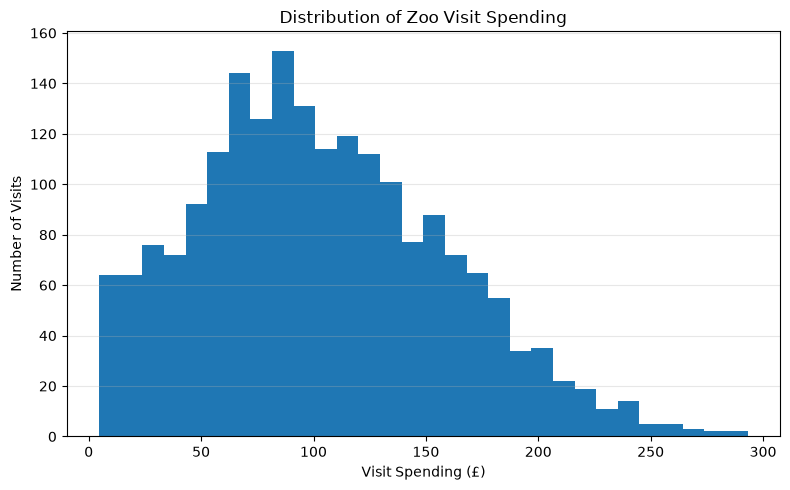

In [129]:
# Show the distribution of visitor spending
# This helps us understand whether most visitors spend similar amounts
# or whether spending varies greatly between groups

plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["VisitSpending"],
    bins=30
)

plt.title("Distribution of Zoo Visit Spending")
plt.xlabel("Visit Spending (£)")
plt.ylabel("Number of Visits")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [130]:
# Select the numerical columns

numeric_columns = [
    "VisitSpending",
    "PartySize",
    "MilesFromZoo",
    "Member",
    "NumberOfChildren",
    "VisitDurationHours",
    "WeekendVisit",
    "SpecialEvent",
    "AdvanceBooking"
]


# Calculate correlations with VisitSpending

correlations = clean_df[numeric_columns].corr()["VisitSpending"]


# Sort the correlations from highest to lowest

correlations = correlations.sort_values(
    ascending=False
)


print("Correlation with VisitSpending:")
print(correlations)

Correlation with VisitSpending:
VisitSpending         1.000000
MilesFromZoo          0.754489
PartySize             0.446365
VisitDurationHours    0.350828
NumberOfChildren      0.319963
SpecialEvent          0.078813
AdvanceBooking        0.030827
WeekendVisit          0.030451
Member               -0.356659
Name: VisitSpending, dtype: float64


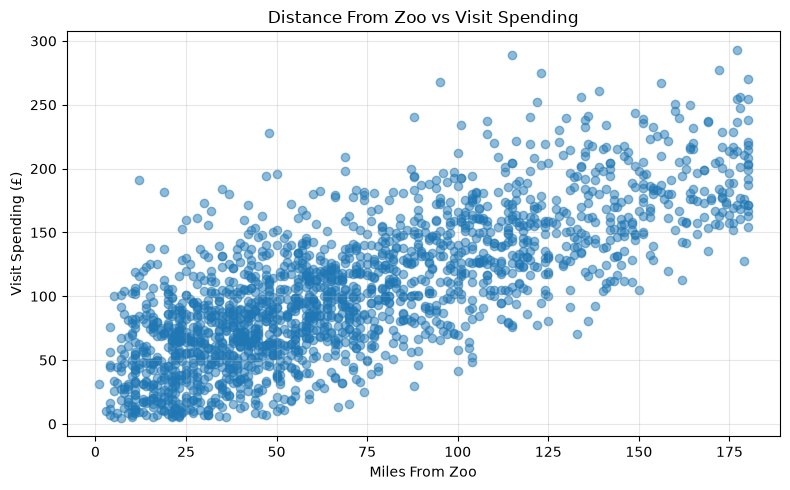

In [131]:
# Compare distance from the zoo with visitor spending
# The initial correlation check shows that distance has a strong relationship
# with VisitSpending

plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["MilesFromZoo"],
    clean_df["VisitSpending"],
    alpha=0.5
)

plt.title("Distance From Zoo vs Visit Spending")
plt.xlabel("Miles From Zoo")
plt.ylabel("Visit Spending (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

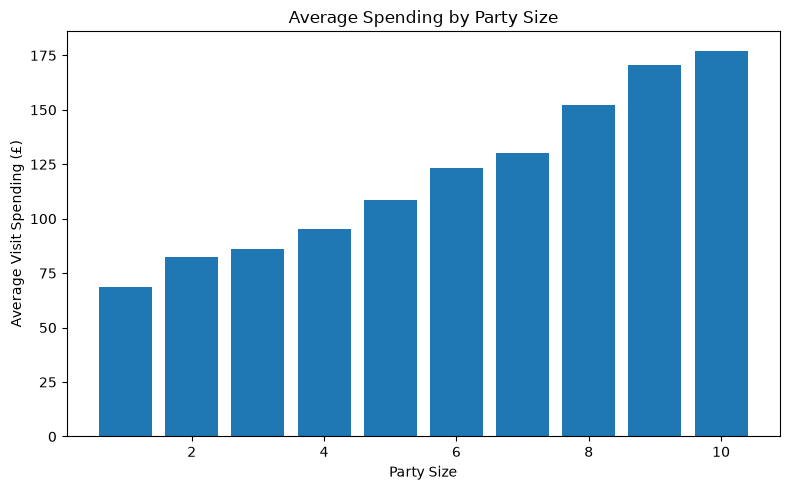

In [132]:
# Calculate average spending for each party size

party_spending = clean_df.groupby(
    "PartySize"
)["VisitSpending"].mean()


# Plot the average spending

plt.figure(figsize=(8, 5))

plt.bar(
    party_spending.index,
    party_spending.values
)

plt.title("Average Spending by Party Size")
plt.xlabel("Party Size")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

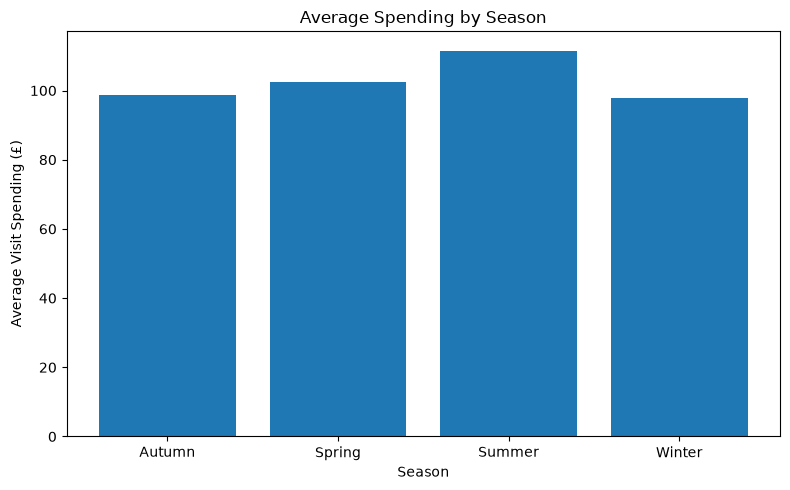

In [133]:
# Calculate average spending for each season

season_spending = clean_df.groupby(
    "Season"
)["VisitSpending"].mean()


# Plot average spending by season

plt.figure(figsize=(8, 5))

plt.bar(
    season_spending.index,
    season_spending.values
)

plt.title("Average Spending by Season")
plt.xlabel("Season")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

Average spending by membership status:
Member
0    126.196313
1     86.551774
Name: VisitSpending, dtype: float64


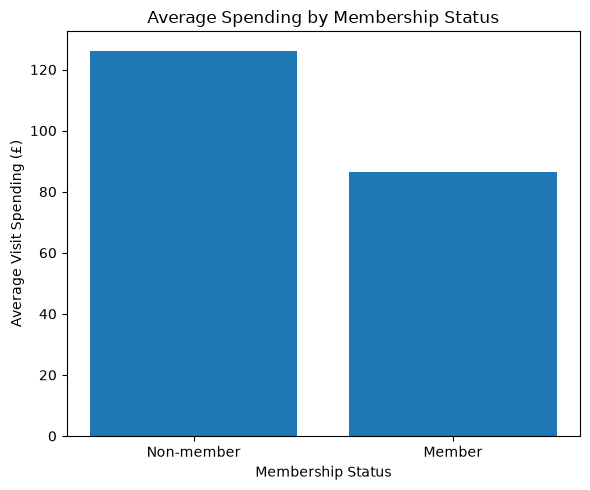

In [134]:
# Compare average spending between members and non-members

member_spending = clean_df.groupby(
    "Member"
)["VisitSpending"].mean()


print("Average spending by membership status:")
print(member_spending)


plt.figure(figsize=(6, 5))

plt.bar(
    ["Non-member", "Member"],
    member_spending.values
)

plt.title("Average Spending by Membership Status")
plt.xlabel("Membership Status")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

### Correlation Heatmap

A correlation heatmap was chosen because it shows the relationship between `VisitSpending` and every numerical feature in one view, and it also shows whether the input features are correlated with each other. The scatter plot above is better for studying one feature in detail, and the bar charts are better for the categorical features.

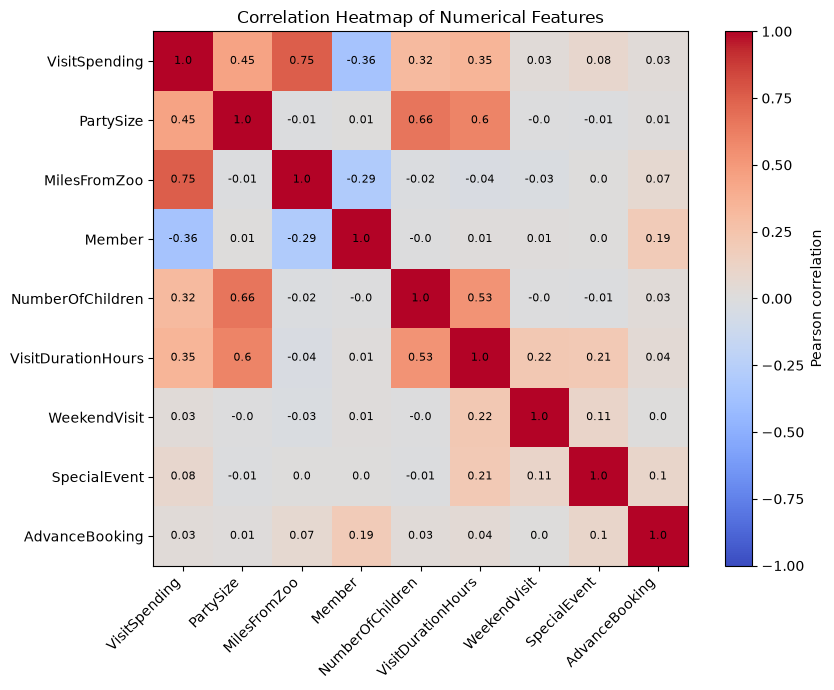

In [135]:
# Calculate the correlation between every pair of numerical columns

corr_matrix = clean_df[numeric_columns].corr()


# Draw the correlations as a coloured grid

plt.figure(figsize=(9, 7))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson correlation")

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)


# Write the correlation value inside each square

for i in range(len(corr_matrix.columns)):

    for j in range(len(corr_matrix.columns)):

        plt.text(j, i, round(corr_matrix.iloc[i, j], 2), ha="center", va="center", fontsize=8)


plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [136]:
# Check the target variable for skew and for unusually large or small values
# A value is flagged as an outlier if it is more than 1.5 x IQR outside the middle 50% of the data

spending = clean_df["VisitSpending"]

q1 = spending.quantile(0.25)
q3 = spending.quantile(0.75)
iqr = q3 - q1

outliers = spending[ (spending < q1 - 1.5 * iqr) | (spending > q3 + 1.5 * iqr) ]


print("Skewness of VisitSpending:", round(spending.skew(), 3))
print("Number of outliers:", len(outliers))
print("Smallest spending:", spending.min())
print("Largest spending:", spending.max())

Skewness of VisitSpending: 0.428
Number of outliers: 10
Smallest spending: 4.59
Largest spending: 293.11


The exploratory analysis shows that several visitor characteristics are associated with spending. `MilesFromZoo` has the strongest correlation with `VisitSpending` (0.75), followed by `PartySize` (0.45), `VisitDurationHours` (0.35) and `NumberOfChildren` (0.32), while membership is negatively correlated (-0.36). Differences are also visible between categories such as season and membership status.

The heatmap also shows that `PartySize`, `NumberOfChildren` and `VisitDurationHours` are correlated with each other (0.53 to 0.66). Correlated inputs can make the coefficients of a linear model unstable, which is one reason for comparing regularised models later. `VisitSpending` is only mildly right-skewed (0.43) and 10 high-spending visits were flagged as outliers. They were kept because they are plausible large-group visits rather than errors.

These relationships justify using the available variables as predictors, although the observed associations should not be interpreted as proof of causation.

## A3. Data Preparation

`VisitSpending` is used as the target variable, while all remaining columns are used as input features. The data is divided into training and test sets so that final model performance can be measured using observations that were not used for training.

In [137]:
# VisitSpending is the value we want the model to predict

y = clean_df["VisitSpending"]


# X contains all the information the model can use to make the prediction

X = clean_df.drop(
    "VisitSpending",
    axis=1
)


print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (1990, 10)
Target data shape: (1990,)


In [138]:
# Split the dataset into training and test data
#
# 80% is used to train the models
# 20% is kept separate to test how well the models work on unseen data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED
)


print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 1592
Testing rows: 398


In [139]:
# These columns contain numerical values

numerical_columns = [
    "PartySize",
    "MilesFromZoo",
    "Member",
    "NumberOfChildren",
    "VisitDurationHours",
    "WeekendVisit",
    "SpecialEvent",
    "AdvanceBooking"
]


# These columns contain text categories

categorical_columns = [
    "Season",
    "WeatherCondition"
]

### Missing Values and Categorical Encoding

Missing numerical values are replaced using the median calculated from the training set because the median is less sensitive to extreme values than the mean. Missing categorical values are replaced using the most frequent training-set category.

The replacement values are calculated from the training data and then applied to the test data to avoid using information from the test set during model preparation. The categorical variables `Season` and `WeatherCondition` are converted into dummy variables so that they can be used by the regression models.

In [140]:
# Fill missing numerical values using the median from the training data
#
# We use values from the training set only so information from the test set
# does not influence the model during training

for column in numerical_columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(
        median_value
    )

    X_test[column] = X_test[column].fillna(
        median_value
    )

In [141]:
# Fill missing categorical values using the most common value
# from the training data

for column in categorical_columns:

    most_common_value = X_train[column].mode()[0]

    X_train[column] = X_train[column].fillna(
        most_common_value
    )

    X_test[column] = X_test[column].fillna(
        most_common_value
    )

In [142]:
# Machine learning models need numerical inputs
#
# get_dummies converts categories such as Summer, Winter, Sunny and Rainy
# into separate 0/1 columns

X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=True
)


# Make sure the training and test sets contain exactly the same columns

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)


print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (1592, 13)
Test data shape: (398, 13)


In [143]:
# Check that no missing values remain

print(
    "Missing values in training data:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in test data:",
    X_test.isnull().sum().sum()
)


# Show the final model input columns

print("\nFinal input columns:")

print(X_train.columns.tolist())

Missing values in training data: 0
Missing values in test data: 0

Final input columns:
['PartySize', 'MilesFromZoo', 'Member', 'NumberOfChildren', 'VisitDurationHours', 'WeekendVisit', 'SpecialEvent', 'AdvanceBooking', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'WeatherCondition_Rainy', 'WeatherCondition_Sunny']


## A4. Regression Models

Two regression approaches are trained first. Linear Regression provides a simple model for learning linear relationships between the features and visitor spending. Random Forest Regression provides a more flexible non-linear approach by combining predictions from multiple decision trees.

In [144]:
# Create a Linear Regression model
#
# This is used as a simple baseline model.
# It estimates spending using a linear relationship between the features
# and VisitSpending.

linear_model = LinearRegression()


# Train the model using the training data

linear_model.fit(
    X_train,
    y_train
)


print("Linear Regression training complete.")

Linear Regression training complete.


In [145]:
# Create a Random Forest regression model
#
# A Random Forest combines many decision trees.
# It can learn more complicated and non-linear relationships.
#
# n_estimators=100 means that the model uses 100 decision trees.

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_SEED
)


# Train the model

random_forest_model.fit(
    X_train,
    y_train
)


print("Random Forest training complete.")

Random Forest training complete.


In [146]:
# Use both trained models to predict spending for the test data

linear_predictions = linear_model.predict(
    X_test
)

random_forest_predictions = random_forest_model.predict(
    X_test
)

### Additional Regression Models

Four more models were added so that linear, regularised and tree-based approaches can be compared:

- **Ridge Regression** adds a penalty on large coefficients, which helps when input features are correlated.
- **Lasso Regression** also penalises coefficients and can reduce unhelpful ones to exactly zero.
- **Decision Tree** and a **tuned Random Forest** can capture non-linear relationships.

The penalty strength (`alpha`) and the tree depths are chosen using 5-fold cross-validation on the **training data only**, so the test set plays no part in these choices. Ridge and Lasso use standardised features because their penalty depends on the size of each feature. The scaler is fitted on the training data before cross-validation, which is a small simplification.

In [147]:
# Ridge and Lasso Regression need all features on a similar scale
# StandardScaler changes every column to have a mean of 0 and a standard deviation of 1
#
# The scaler learns the mean and spread from the training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# 5-fold cross-validation splits the training data into 5 parts
# Each part is used once as a small validation set
# This tests each model several times without touching the real test set

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

In [148]:
# Try different penalty strengths (alpha) for Ridge Regression
# The alpha with the lowest cross-validated RMSE is kept

alpha_values = [0.01, 0.1, 1, 10, 100]

best_ridge_alpha = 0
best_ridge_rmse = 1000000


for alpha in alpha_values:

    ridge_scores = cross_val_score(
        Ridge(alpha=alpha),
        X_train_scaled,
        y_train,
        cv=kfold,
        scoring="neg_root_mean_squared_error"
    )

    # The scores are negative, so the sign is flipped to get the RMSE
    ridge_rmse = -ridge_scores.mean()

    print("Ridge alpha:", alpha, " CV RMSE:", round(ridge_rmse, 3))

    if ridge_rmse < best_ridge_rmse:

        best_ridge_rmse = ridge_rmse
        best_ridge_alpha = alpha


print("\nBest Ridge alpha:", best_ridge_alpha)

Ridge alpha: 0.01  CV RMSE: 24.267
Ridge alpha: 0.1  CV RMSE: 24.267
Ridge alpha: 1  CV RMSE: 24.267
Ridge alpha: 10  CV RMSE: 24.267
Ridge alpha: 100  CV RMSE: 24.499

Best Ridge alpha: 1


In [149]:
# Try different penalty strengths (alpha) for Lasso Regression

alpha_values = [0.001, 0.01, 0.1, 1, 10]

best_lasso_alpha = 0
best_lasso_rmse = 1000000


for alpha in alpha_values:

    lasso_scores = cross_val_score(
        Lasso(alpha=alpha, max_iter=10000),
        X_train_scaled,
        y_train,
        cv=kfold,
        scoring="neg_root_mean_squared_error"
    )

    lasso_rmse = -lasso_scores.mean()

    print("Lasso alpha:", alpha, " CV RMSE:", round(lasso_rmse, 3))

    if lasso_rmse < best_lasso_rmse:

        best_lasso_rmse = lasso_rmse
        best_lasso_alpha = alpha


print("\nBest Lasso alpha:", best_lasso_alpha)

Lasso alpha: 0.001  CV RMSE: 24.267
Lasso alpha: 0.01  CV RMSE: 24.267
Lasso alpha: 0.1  CV RMSE: 24.261
Lasso alpha: 1  CV RMSE: 24.376
Lasso alpha: 10  CV RMSE: 29.946

Best Lasso alpha: 0.1


In [150]:
# Try different maximum depths for the Decision Tree
# A very deep tree memorises the training data, a very shallow tree is too simple

depth_values = [3, 5, 7, 10]

best_tree_depth = 0
best_tree_rmse = 1000000


for depth in depth_values:

    tree_scores = cross_val_score(
        DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_SEED),
        X_train,
        y_train,
        cv=kfold,
        scoring="neg_root_mean_squared_error"
    )

    tree_rmse = -tree_scores.mean()

    print("Tree depth:", depth, " CV RMSE:", round(tree_rmse, 3))

    if tree_rmse < best_tree_rmse:

        best_tree_rmse = tree_rmse
        best_tree_depth = depth


print("\nBest tree depth:", best_tree_depth)

Tree depth: 3  CV RMSE: 32.743
Tree depth: 5  CV RMSE: 29.063
Tree depth: 7  CV RMSE: 29.909
Tree depth: 10  CV RMSE: 33.976

Best tree depth: 5


In [151]:
# Try different maximum depths for the Random Forest
# The earlier Random Forest used the default settings, so this version is tuned

forest_depth_values = [5, 10, 20]

best_forest_depth = 0
best_forest_rmse = 1000000


for depth in forest_depth_values:

    forest_scores = cross_val_score(
        RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=RANDOM_SEED),
        X_train,
        y_train,
        cv=kfold,
        scoring="neg_root_mean_squared_error"
    )

    forest_rmse = -forest_scores.mean()

    print("Forest depth:", depth, " CV RMSE:", round(forest_rmse, 3))

    if forest_rmse < best_forest_rmse:

        best_forest_rmse = forest_rmse
        best_forest_depth = depth


print("\nBest forest depth:", best_forest_depth)

Forest depth: 5  CV RMSE: 26.532
Forest depth: 10  CV RMSE: 25.774
Forest depth: 20  CV RMSE: 25.955

Best forest depth: 10


In [152]:
# Train the new models using the best settings found above

ridge_model = Ridge(alpha=best_ridge_alpha)
ridge_model.fit(X_train_scaled, y_train)


lasso_model = Lasso(alpha=best_lasso_alpha, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)


tree_model = DecisionTreeRegressor(max_depth=best_tree_depth, random_state=RANDOM_SEED)
tree_model.fit(X_train, y_train)


tuned_forest_model = RandomForestRegressor(n_estimators=100, max_depth=best_forest_depth, random_state=RANDOM_SEED)
tuned_forest_model.fit(X_train, y_train)


print("Ridge, Lasso, Decision Tree and tuned Random Forest training complete.")

Ridge, Lasso, Decision Tree and tuned Random Forest training complete.


## A5. Model Evaluation

The models are evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²). Lower MSE and RMSE values indicate smaller prediction errors, while a higher R² indicates that the model explains a greater proportion of the variation in visitor spending.
Mean Absolute Error (MAE) is also reported in the full comparison.”

In [153]:
# Calculate the prediction error for Linear Regression

linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    linear_mse
)


# R-squared shows how much of the variation in spending
# is explained by the model

linear_r2 = r2_score(
    y_test,
    linear_predictions
)


print("Linear Regression")

print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

Linear Regression
MSE: 527.0161737479045
RMSE: 22.95683283355752
R2: 0.8326374385568917


In [154]:
# Calculate the same evaluation measures for Random Forest

rf_mse = mean_squared_error(
    y_test,
    random_forest_predictions
)

rf_rmse = np.sqrt(
    rf_mse
)

rf_r2 = r2_score(
    y_test,
    random_forest_predictions
)


print("Random Forest")

print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

Random Forest
MSE: 645.5339228847738
RMSE: 25.4073596204874
R2: 0.7950001988286355


In [155]:
# Compare the performance of both regression models

regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MSE": [linear_mse, rf_mse],
    "RMSE": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

display(regression_results)

,Model,MSE,RMSE,R2
0,Linear Regression,527.016174,22.956833,0.832637
1,Random Forest,645.533923,25.407360,0.795000


### Initial Comparison

The first comparison above uses Linear Regression and a Random Forest with default settings. The remaining models are added below so that all approaches can be compared in the same way.

### Comparison of All Regression Models

All five models are compared using the cross-validated RMSE from the training data. The model with the lowest cross-validated RMSE is selected, and the test set is then used once to report how every model performs on unseen visits.

The cross-validated values of the tuned models are slightly optimistic because their settings were chosen using the same folds.

In [156]:
# Cross-validated RMSE for Linear Regression
# (the other models already have theirs from the tuning loops above)

linear_scores = cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=kfold,
    scoring="neg_root_mean_squared_error"
)

linear_cv_rmse = -linear_scores.mean()


# Test-set predictions for the new models
# (Ridge and Lasso use the scaled data)

ridge_predictions = ridge_model.predict(X_test_scaled)

lasso_predictions = lasso_model.predict(X_test_scaled)

tree_predictions = tree_model.predict(X_test)

tuned_forest_predictions = tuned_forest_model.predict(X_test)

In [157]:
# Put the models into lists so the same code can evaluate every model

model_names = [
    "Linear Regression",
    "Ridge Regression",
    "Lasso Regression",
    "Decision Tree (tuned)",
    "Random Forest (tuned)"
]

model_objects = [linear_model, ridge_model, lasso_model, tree_model, tuned_forest_model]

model_predictions = [linear_predictions, ridge_predictions, lasso_predictions, tree_predictions, tuned_forest_predictions]

cv_rmse_values = [linear_cv_rmse, best_ridge_rmse, best_lasso_rmse, best_tree_rmse, best_forest_rmse]


# Calculate the test-set measures for each model

results_rows = []

for i in range( len(model_names) ):

    mse = mean_squared_error( y_test, model_predictions[i] )

    results_rows.append([
        model_names[i],
        cv_rmse_values[i],
        mse,
        np.sqrt(mse),
        mean_absolute_error( y_test, model_predictions[i] ),
        r2_score( y_test, model_predictions[i] )
    ])


regression_results_full = pd.DataFrame(
    results_rows,
    columns=["Model", "CV RMSE (train)", "Test MSE", "Test RMSE", "Test MAE", "Test R2"]
)

display( regression_results_full.round(3) )

,Model,CV RMSE (train),Test MSE,Test RMSE,Test MAE,Test R2
0,Linear Regression,24.267,527.016,22.957,18.046,0.833
1,Ridge Regression,24.267,526.899,22.954,18.044,0.833
2,Lasso Regression,24.261,526.231,22.940,18.033,0.833
3,Decision Tree (tuned),29.063,875.117,29.582,23.420,0.722
4,Random Forest (tuned),25.774,630.236,25.105,19.759,0.800


In [158]:
# Select the model with the lowest cross-validated RMSE
# The test set is not used to make this choice

best_index = regression_results_full["CV RMSE (train)"].idxmin()

best_model_name = model_names[best_index]

best_model = model_objects[best_index]

best_predictions = model_predictions[best_index]


print("Selected model:", best_model_name)

Selected model: Lasso Regression


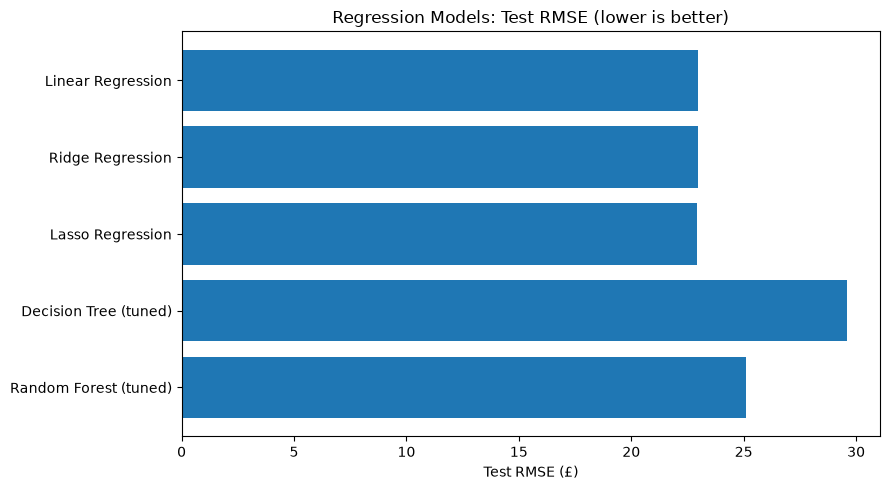

In [159]:
# Compare the test RMSE of all models

plt.figure(figsize=(9, 5))

plt.barh(
    regression_results_full["Model"],
    regression_results_full["Test RMSE"]
)

plt.gca().invert_yaxis()

plt.title("Regression Models: Test RMSE (lower is better)")
plt.xlabel("Test RMSE (£)")

plt.tight_layout()
plt.show()

### Actual vs Predicted Spending

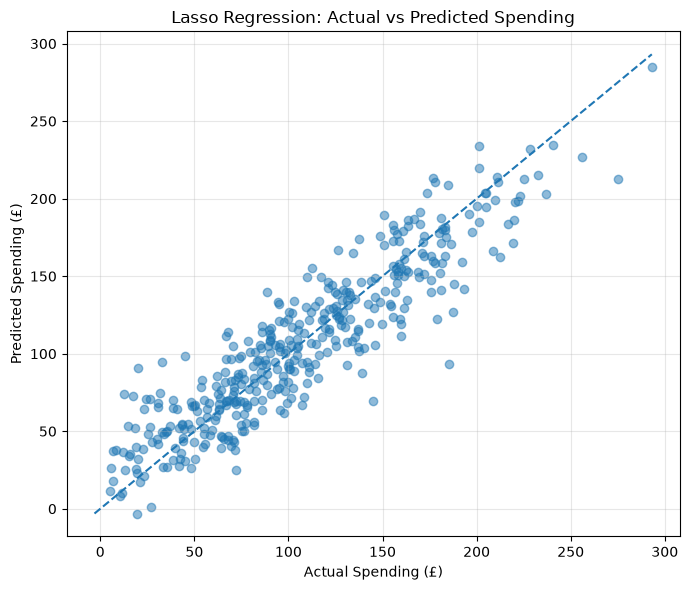

In [160]:
# Plot actual spending against the predictions of the selected model
#
# Predictions closer to the diagonal line are more accurate.

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)


# Draw a reference line showing perfect predictions

minimum_value = min(
    y_test.min(),
    best_predictions.min()
)

maximum_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)


plt.title(best_model_name + ": Actual vs Predicted Spending")
plt.xlabel("Actual Spending (£)")
plt.ylabel("Predicted Spending (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Residual Analysis

A residual is the actual spending minus the predicted spending. If the model is suitable, the residuals should be scattered randomly around zero with a similar spread for all predicted values, and their histogram should look roughly bell-shaped. A curve or a funnel shape in the scatter plot would suggest that the model is missing a pattern.

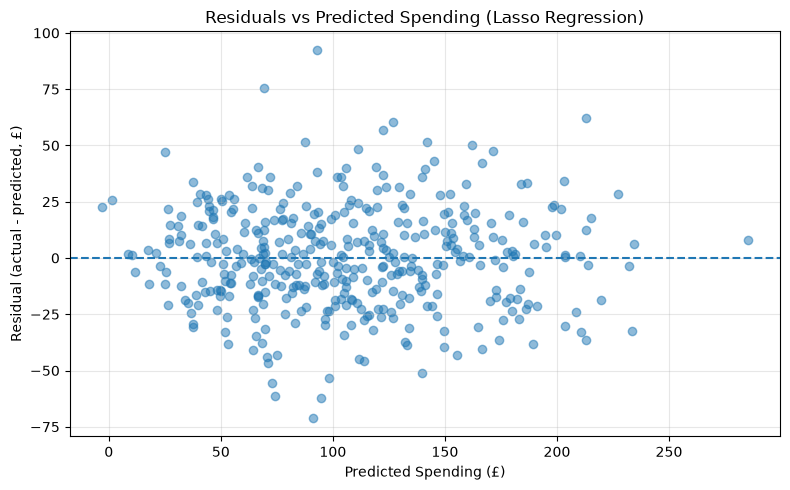

In [161]:
# Calculate the residuals for the selected model

residuals = y_test - best_predictions


# Residuals plotted against the predicted spending

plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted Spending (" + best_model_name + ")")
plt.xlabel("Predicted Spending (£)")
plt.ylabel("Residual (actual - predicted, £)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

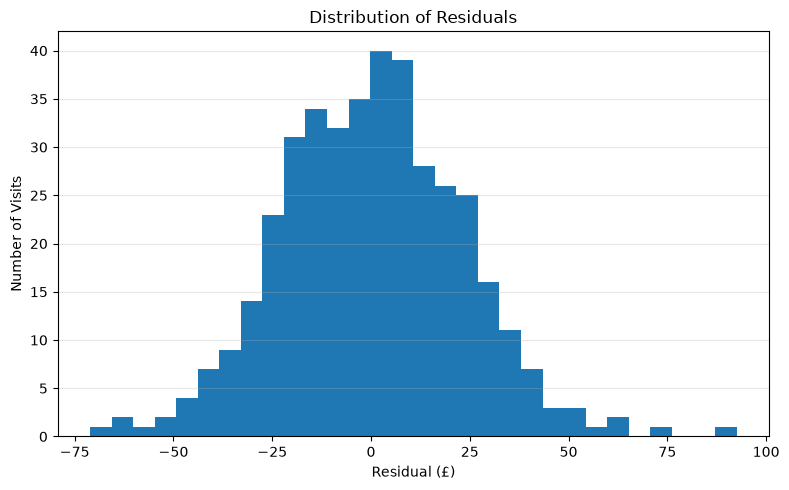

Mean residual: 0.18
Standard deviation of residuals: 22.97


In [162]:
# Distribution of the residuals

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30
)

plt.title("Distribution of Residuals")
plt.xlabel("Residual (£)")
plt.ylabel("Number of Visits")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


print("Mean residual:", round(residuals.mean(), 2))
print("Standard deviation of residuals:", round(residuals.std(), 2))

### Linear Regression Coefficients

Each coefficient shows how much the predicted spending changes (in pounds) when that feature increases by one unit and the other features stay the same. For the dummy variables it is the difference compared with the category that was dropped. These coefficients describe the model only and do not show cause and effect.

In [163]:
# Show the coefficients of the Linear Regression model

coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient (£ per unit)": linear_model.coef_
})

coefficient_table = coefficient_table.sort_values(
    by="Coefficient (£ per unit)",
    ascending=False
)

display(coefficient_table.round(3))

,Feature,Coefficient (£ per unit)
6,SpecialEvent,12.151
0,PartySize,10.273
9,Season_Summer,6.820
4,VisitDurationHours,4.002
12,WeatherCondition_Sunny,3.022
5,WeekendVisit,2.371
3,NumberOfChildren,1.604
1,MilesFromZoo,0.879
8,Season_Spring,0.836
7,AdvanceBooking,-1.324


In [164]:
# Random Forest can show how much it relied on each feature
# when making its predictions

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})


# Sort features from most important to least important

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


display(feature_importance)

,Feature,Importance
1,MilesFromZoo,0.612295
0,PartySize,0.212152
4,VisitDurationHours,0.070152
2,Member,0.022217
3,NumberOfChildren,0.016799
9,Season_Summer,0.010202
12,WeatherCondition_Sunny,0.009141
5,WeekendVisit,0.008865
6,SpecialEvent,0.008827
7,AdvanceBooking,0.008448


### Feature Importance

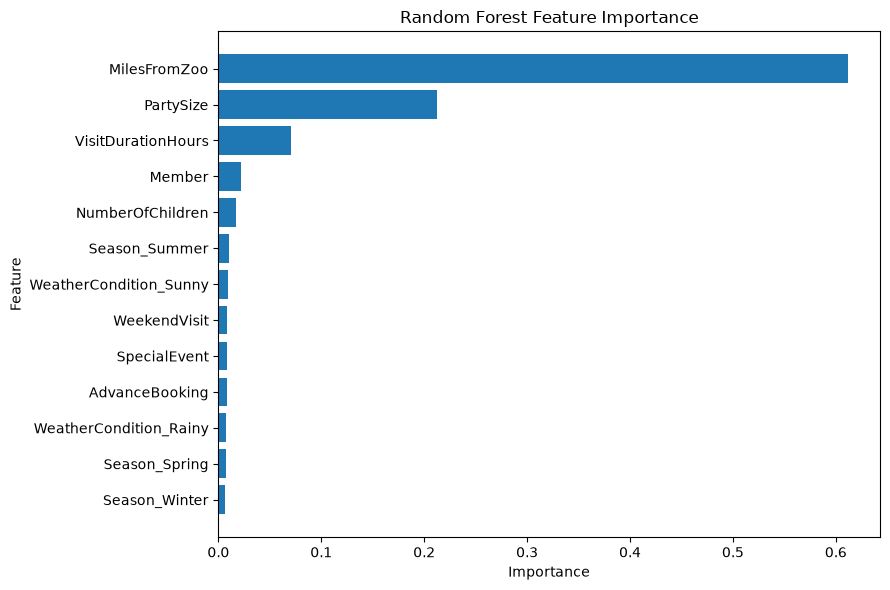

In [165]:
# Plot the feature importance values

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")


# Put the most important feature at the top

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

The Random Forest feature-importance results show that `MilesFromZoo` was the most influential input, followed by `PartySize` and `VisitDurationHours`. Feature importance indicates how much the Random Forest relied on each variable when making predictions, but it does not demonstrate that these variables directly cause changes in visitor spending.

In [166]:
# Print a short summary of the regression results

best_row = regression_results_full.loc[best_index]


print("PART A CONCLUSION")

print()

print("Selected model:", best_model_name)

print("Cross-validated RMSE on the training data:", round(best_row["CV RMSE (train)"], 2))

print("Test RMSE:", round(best_row["Test RMSE"], 2))

print("Test R2:", round(best_row["Test R2"], 3))


print()

print("Its RMSE means that predictions were typically about £", round(best_row["Test RMSE"], 2), "away from the actual spending value.")

print("The R2 score shows that the model explained about", round(best_row["Test R2"] * 100, 1), "% of the variation in VisitSpending.")

PART A CONCLUSION

Selected model: Lasso Regression
Cross-validated RMSE on the training data: 24.26
Test RMSE: 22.94
Test R2: 0.833

Its RMSE means that predictions were typically about £ 22.94 away from the actual spending value.
The R2 score shows that the model explained about 83.3 % of the variation in VisitSpending.


### Estimating the Budget for a New Visit

The Smart Zoo Visit Assistant needs to give a family an indicative budget before they travel. The cell below enters the details of one example family, prepares them in exactly the same way as the training data, and predicts the spending with the selected model.

In [167]:
# Details of an example visit: 4 people (2 children), 12 miles from the zoo, summer weekend,
# booked in advance, sunny weather, no membership

new_visit = pd.DataFrame({
    "PartySize": [4],
    "MilesFromZoo": [12],
    "Member": [0],
    "NumberOfChildren": [2],
    "VisitDurationHours": [5],
    "WeekendVisit": [1],
    "Season": ["Summer"],
    "SpecialEvent": [0],
    "AdvanceBooking": [1],
    "WeatherCondition": ["Sunny"]
})


# Convert the categories to dummy variables, then make sure the columns match the training data exactly
# (reindex adds any missing dummy columns with the value 0)

new_visit = pd.get_dummies(new_visit, columns=categorical_columns)

new_visit = new_visit.reindex(columns=X_train.columns, fill_value=0)


# Ridge and Lasso were trained on scaled data, so the new visit must be scaled in the same way

if best_model_name in ["Ridge Regression", "Lasso Regression"]:

    new_visit = scaler.transform(new_visit)


estimated_spending = best_model.predict(new_visit)[0]


print("Estimated visit budget: £", round(estimated_spending, 2))
print("Typical error of the selected model: about £", round(best_row["Test RMSE"], 2))

Estimated visit budget: £ 71.73
Typical error of the selected model: about £ 22.94


## A6. Part A Conclusion

Five regression models were compared using 5-fold cross-validation on the training data. The model with the lowest cross-validated RMSE was selected, and the test set was used only once to report its final performance (see the summary above).

Linear, Ridge and Lasso Regression performed almost identically, and the tuned Random Forest and Decision Tree did not improve on them. This suggests that the relationship between the visit features and spending is mostly linear. The model should be treated as an indicative spending estimate rather than an exact future bill.

**Limitations**

- Performance was measured on a single 80/20 split. Cross-validation shows how stable the error is, but a new set of visitors may behave differently.
- `VisitDurationHours` is defined as the time spent inside the zoo, but the scenario describes a planned duration. Before a visit only the planned value is known, so the deployed model depends on how well visitors can predict it.
- Missing values were filled with the training median or most common category. Fewer than 2% of the values in any column were missing, so this should have a small effect, but it can reduce variation in the data.
- The data is historical, so the model assumes that future visitors spend in the same way as past visitors (prices, events and inflation change over time).
- Residual plot: The residual plot shows the residuals scattered around zero with no clear curve or funnel shape, and their histogram is roughly bell-shaped and centred near zero (mean £0.18) with a slightly longer right tail. This suggests the linear assumptions are reasonable. A few large residuals (about −£70 to +£90) are visits the features cannot explain, and one or two predictions are close to or below zero, so predicted spending could be capped at £0 in practice.

# Part B - Animal Image Classification

The aim of Part B is to classify visitor animal photographs into one of 10 animal categories. The image dataset is first inspected and prepared before a baseline CNN, an improved CNN and a transfer-learning model are trained, evaluated and compared.

## B1. Image Dataset Inspection

In [168]:
# Import libraries needed to inspect the image dataset

import os
import hashlib

from PIL import Image
import matplotlib.pyplot as plt


# Path to the folder that contains the animal class folders
image_folder = "Image_dataset"

In [169]:
# Get the names of the class folders
# Each folder represents one animal class

class_names = []


for item in os.listdir(image_folder):

    item_path = os.path.join(
        image_folder,
        item
    )

    # Only keep folders
    if os.path.isdir(item_path):
        class_names.append(item)


# Sort 
class_names.sort()


print("Classes found:")
print(class_names)

print("\nNumber of classes:")
print(len(class_names))

Classes found:
['Afghan_hound', 'Appenzeller', 'Cat', 'Lion', 'Pig', 'Tigers', 'Tortoise', 'Toy poodle', 'Weimaraner', 'Whippet']

Number of classes:
10


### Class Distribution

In [170]:
# Count how many image files are there

image_counts = {}
for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )

    count = 0


    for file_name in os.listdir(class_path):

        # Count common image file types
        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):
            count += 1


    image_counts[class_name] = count


# number of images in each class
for class_name in class_names:

    print( class_name, ":", image_counts[class_name] )

Afghan_hound : 50
Appenzeller : 50
Cat : 50
Lion : 50
Pig : 50
Tigers : 50
Tortoise : 50
Toy poodle : 50
Weimaraner : 50
Whippet : 50


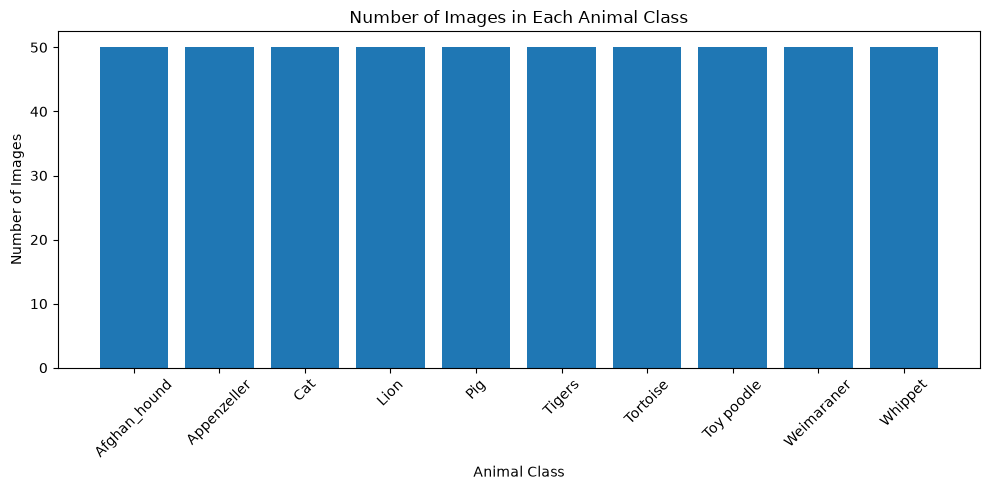

In [171]:
# Plot the class sizes
# This helps us check whether the dataset is balanced

plt.figure( figsize=(10, 5) )


plt.bar( image_counts.keys(), image_counts.values() )


plt.title( "Number of Images in Each Animal Class" )
plt.xlabel( "Animal Class" ) 
plt.ylabel( "Number of Images" ) 
plt.xticks( rotation=45 )


plt.tight_layout()
plt.show()

The original image dataset contains 500 images across 10 animal classes, with 50 images in each class. This indicates that the original dataset is evenly balanced before duplicate images are removed.

### Representative Images

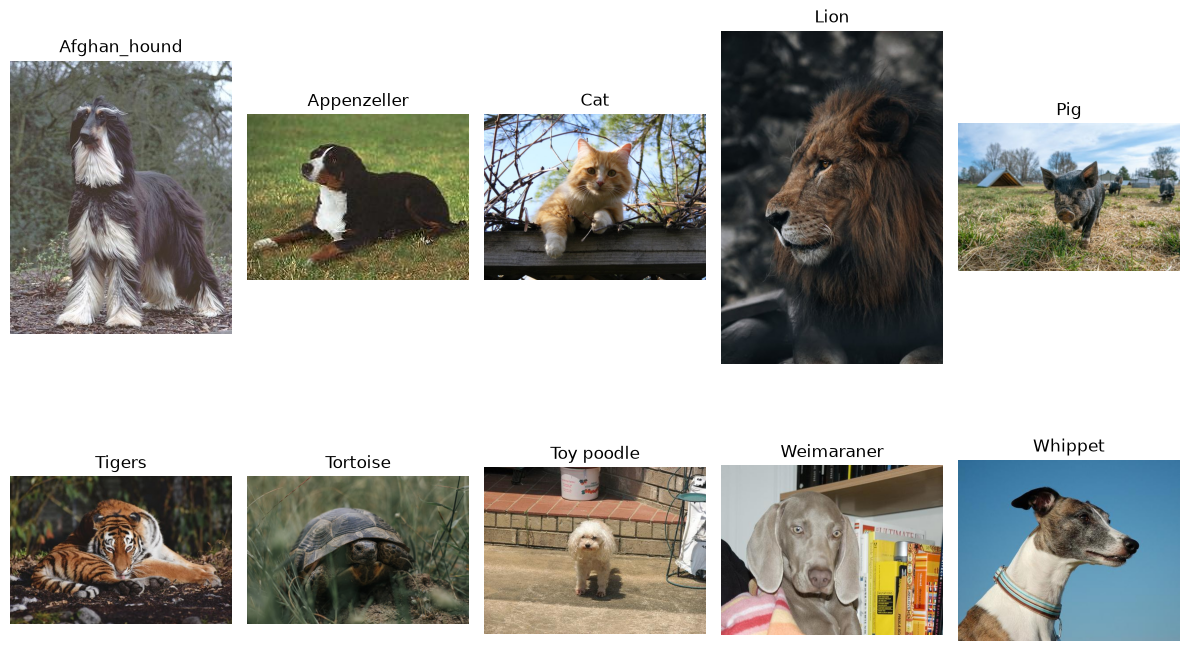

In [172]:
# Show one example image from each animal class
# This gives us a quick visual check of the dataset

plt.figure( figsize=(12, 8) )


image_number = 1


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    # Get the image files from this class
    image_files = []


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):
            image_files.append(file_name)


    # Use the first image in the folder
    example_file = image_files[0]


    example_path = os.path.join( class_path, example_file )


    image = Image.open( example_path )


    plt.subplot( 2, 5, image_number )


    plt.imshow(image)

    plt.title( class_name )

    plt.axis("off")


    image_number += 1


plt.tight_layout()
plt.show()

The representative images show noticeable variation in animal appearance, pose, background and framing. These differences make the classification task more challenging because the model must learn features associated with the animal rather than relying only on a consistent background or image layout.

### Image Dimensions and Format

In [173]:
# Check the image dimensions
# CNN models need images to have the same input size,
# so this tells us whether resizing will be needed

image_sizes = []


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            image = Image.open( image_path ) 
            image_sizes.append( image.size )


# Show a few image sizes
print( "First 20 image sizes:" ) 
print( image_sizes[:20] )


# Show how many different image sizes exist
unique_sizes = set( image_sizes ) 
print( "\nNumber of different image sizes:" ) 
print( len(unique_sizes) )

First 20 image sizes:
[(406, 500), (480, 360), (500, 388), (348, 500), (363, 500), (374, 500), (500, 333), (333, 500), (500, 375), (377, 500), (357, 500), (342, 500), (333, 500), (378, 500), (473, 500), (334, 500), (334, 500), (397, 480), (333, 500), (500, 333)]

Number of different image sizes:
197


In [174]:
# Check which image formats are used in the dataset

image_formats = set()


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )

    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name ) 
            image = Image.open( image_path ) 
            image_formats.add( image.format )


print( "Image formats found:" ) 
print( image_formats )

Image formats found:
{'JPEG'}


The dataset contains 197 different image dimensions, so resizing is required before the images can be provided to a CNN. All inspected files use the JPEG format.

Eight exact duplicate image pairs were identified. Duplicate copies are excluded before creating the training, validation and test sets so that identical images cannot appear in different subsets and artificially inflate model performance.

In [175]:
# Check for exact duplicate image files
# Duplicate images are important because the same image should not appear
# in both training and test data. That could make the model look better
# than it really is.

image_hashes = {}

duplicate_images = []


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            # Read the image file
            with open( image_path, "rb" ) as file:

                file_data = file.read()


            # Create a unique hash for the image file
            image_hash = hashlib.md5( file_data ).hexdigest()


            # If the same hash already exists,
            # this image is an exact duplicate
            if image_hash in image_hashes:

                duplicate_images.append( ( image_hashes[image_hash], image_path ) )

            else:

                image_hashes[image_hash] = image_path

In [176]:
# Show how many exact duplicate image pairs were found

print( "Number of duplicate image pairs:" ) 
print( len(duplicate_images) )


# Print the duplicate file paths
for first_image, second_image in duplicate_images:

    print()

    print( "Original:", first_image )

    print( "Duplicate:", second_image )

Number of duplicate image pairs:
8

Original: Image_dataset/Lion/l8.jpeg
Duplicate: Image_dataset/Lion/l5.jpeg

Original: Image_dataset/Lion/l39.jpg
Duplicate: Image_dataset/Lion/l44.jpg

Original: Image_dataset/Weimaraner/i13.jpg
Duplicate: Image_dataset/Weimaraner/i25.jpg

Original: Image_dataset/Weimaraner/i14.jpg
Duplicate: Image_dataset/Weimaraner/i24.jpg

Original: Image_dataset/Weimaraner/i12.jpg
Duplicate: Image_dataset/Weimaraner/i26.jpg

Original: Image_dataset/Weimaraner/i10.jpg
Duplicate: Image_dataset/Weimaraner/i27.jpg

Original: Image_dataset/Weimaraner/i15.jpg
Duplicate: Image_dataset/Weimaraner/i23.jpg

Original: Image_dataset/Weimaraner/i18.jpg
Duplicate: Image_dataset/Weimaraner/i22.jpg


In [177]:
# simple summary of the image dataset inspection

total_images = sum( image_counts.values() ) 
print( "IMAGE DATASET SUMMARY" ) 
print() 
print( "Number of classes:", len(class_names) ) 
print( "Total number of images:", total_images ) 
print( "Images per class:" ) 
for class_name in class_names: 
    print( class_name, ":", image_counts[class_name] )



print()

print( "Different image sizes:", len(unique_sizes) ) 
print( "Image formats:", image_formats ) 
print( "Duplicate image pairs:", len(duplicate_images) )

IMAGE DATASET SUMMARY

Number of classes: 10
Total number of images: 500
Images per class:
Afghan_hound : 50
Appenzeller : 50
Cat : 50
Lion : 50
Pig : 50
Tigers : 50
Tortoise : 50
Toy poodle : 50
Weimaraner : 50
Whippet : 50

Different image sizes: 197
Image formats: {'JPEG'}
Duplicate image pairs: 8


## B2. Image Preparation

The duplicate copies identified during inspection are excluded before splitting the dataset. The remaining images are then labelled, divided into training, validation and test sets, resized to a consistent input size and normalised for CNN training.

In [178]:
# Create a list of image paths and labels
# We will skip the duplicate copies found before

image_paths = []
image_labels = []


# Store the duplicate copies that we want to ignore
duplicate_copies = set()


for first_image, second_image in duplicate_images:

    # Keep the first image and ignore the second copy
    duplicate_copies.add(second_image)


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            # Only add the image if it is not a duplicate copy
            if image_path not in duplicate_copies:

                image_paths.append( image_path )

                image_labels.append( class_name )


print( "Images after removing duplicate copies:", len(image_paths) )

Images after removing duplicate copies: 492


### Near-Duplicate Images

Checking for exact duplicates only finds files that are identical byte for byte. A photo that has been resized, recoloured or converted to black and white would not be found, and a near-copy in the test set would make the model look better than it really is.

An *average hash* was therefore used to find images of the same class that are almost identical. Each image is shrunk to a tiny 8 × 8 greyscale picture and the hash records which of the 64 pixels are brighter than average. Near-identical images give almost the same pattern. The hash is only compared within each class, because the aim is to find copies of the same photo. The flagged pairs are displayed so they can be checked by eye, and one image from each pair is removed before the data is split.

In [179]:
# Turn an image into a small pattern of True / False values (the average hash)

def average_hash(path):

    image = Image.open( path ).convert( "L" )

    image = image.resize( ( 8, 8 ) )

    pixels = np.array( image )

    return ( pixels > pixels.mean() ).flatten()


# Calculate the hash of every image

average_hashes = []

for path in image_paths:

    average_hashes.append( average_hash(path) )


# Compare every pair of images from the same class
# If 4 or fewer of the 64 values are different, the images are treated as near-duplicates

near_duplicate_pairs = []

for i in range( len(image_paths) ):

    for j in range( i + 1, len(image_paths) ):

        if image_labels[i] == image_labels[j]:

            differences = np.sum( average_hashes[i] != average_hashes[j] )

            if differences <= 4:

                near_duplicate_pairs.append( ( image_paths[i], image_paths[j] ) )


print( "Possible near-duplicate pairs:", len(near_duplicate_pairs) )

Possible near-duplicate pairs: 7


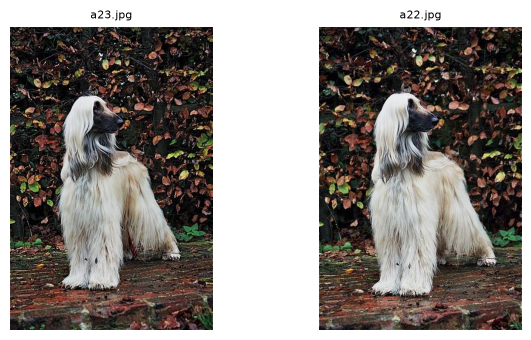

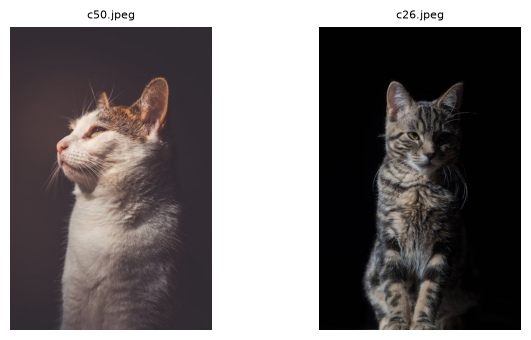

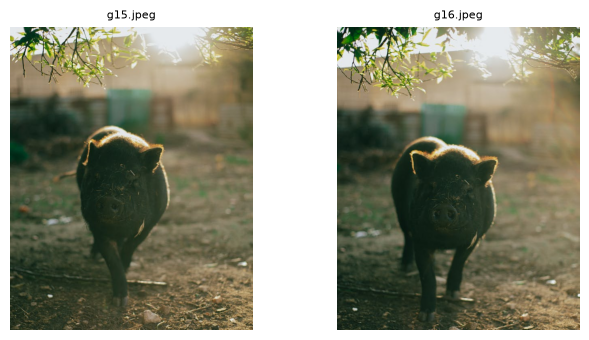

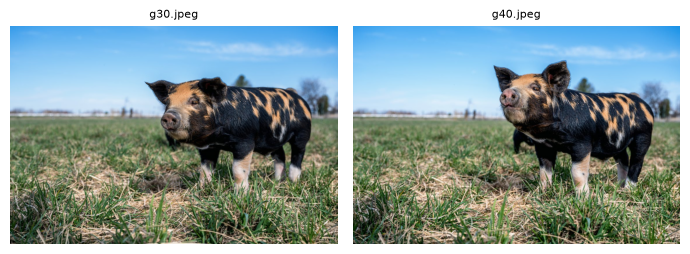

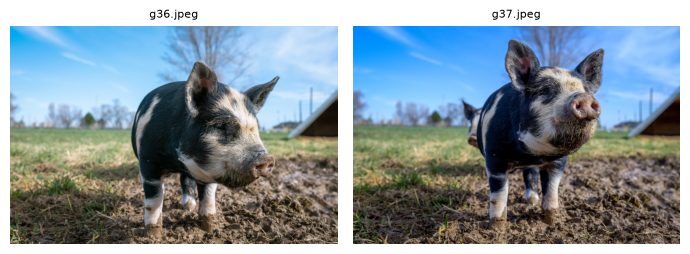

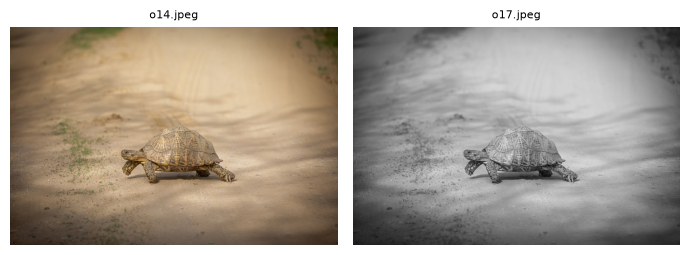

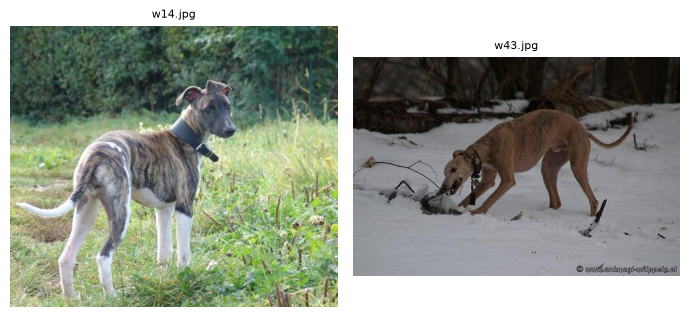

In [180]:
# Show each flagged pair so it can be checked by eye

for first_image, second_image in near_duplicate_pairs:

    plt.figure( figsize=(7, 3.5) )


    plt.subplot( 1, 2, 1 )

    plt.imshow( Image.open( first_image ) )

    plt.title( os.path.basename( first_image ), fontsize=8 )

    plt.axis("off")


    plt.subplot( 1, 2, 2 )

    plt.imshow( Image.open( second_image ) )

    plt.title( os.path.basename( second_image ), fontsize=8 )

    plt.axis("off")


    plt.tight_layout()
    plt.show()

In [181]:
# Keep the first image of each pair and ignore the second copy

near_duplicate_copies = set()

for first_image, second_image in near_duplicate_pairs:

    near_duplicate_copies.add( second_image )


clean_paths = []
clean_labels = []

for path, label in zip( image_paths, image_labels ):

    if path not in near_duplicate_copies:

        clean_paths.append( path )
        clean_labels.append( label )


image_paths = clean_paths
image_labels = clean_labels


print( "Images after removing exact and near-duplicate copies:", len(image_paths) )

Images after removing exact and near-duplicate copies: 485


Checking the flagged pairs by eye showed that five were genuine near-copies (one Afghan hound, three pig and one tortoise pair), while two (cat c50/c26 and whippet w14/w43) were different photos. Removing these two extra images has very little effect on a dataset of this size.
After removing the exact duplicates and the near-duplicate copies, the remaining images are used for the rest of the project. The original dataset was perfectly balanced with 50 images per class, so removing copies can introduce a small amount of class imbalance. The class counts below show how large it is.

In [182]:
# how many usable images remain in each class

clean_class_counts = {}


for class_name in class_names:

    clean_class_counts[class_name] = 0


for label in image_labels:

    clean_class_counts[label] += 1


for class_name in class_names:

    print( class_name, ":", clean_class_counts[class_name] )

Afghan_hound : 49
Appenzeller : 50
Cat : 49
Lion : 48
Pig : 47
Tigers : 50
Tortoise : 49
Toy poodle : 50
Weimaraner : 44
Whippet : 49


### Label Encoding

In [183]:
# Machine learning models work with numerical labels,
# so each animal class is given a number

class_to_number = {}


for index in range( len(class_names) ):

    class_to_number[ class_names[index] ] = index


print( class_to_number )

{'Afghan_hound': 0, 'Appenzeller': 1, 'Cat': 2, 'Lion': 3, 'Pig': 4, 'Tigers': 5, 'Tortoise': 6, 'Toy poodle': 7, 'Weimaraner': 8, 'Whippet': 9}


In [184]:
# Convert each text label into its numerical class value

numerical_labels = []


for label in image_labels:

    numerical_labels.append( class_to_number[label] )


print( numerical_labels[:20] )

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Train, Validation and Test Split

The cleaned dataset is divided into approximately 70% training, 15% validation and 15% test data. Stratified splitting is used so that the class distribution remains as consistent as possible across the three subsets. A fixed random state is used to make the split reproducible.

In [185]:
from sklearn.model_selection import train_test_split

# First split:
# 70% training
# 30% temporary data

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    numerical_labels,
    test_size=0.30,
    random_state=42,
    stratify=numerical_labels
)


# Second split:
# Divide the remaining 30% equally
# 15% validation and 15% test

validation_paths, test_paths, validation_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)


print( "Training images:", len(train_paths) )

print( "Validation images:", len(validation_paths) )

print( "Test images:", len(test_paths) )

Training images: 339
Validation images: 73
Test images: 73


The training set is used to learn the model parameters, the validation set is used to monitor performance during training and support decisions such as early stopping, and the test set is kept separate for final evaluation on unseen images.

### Image Resizing and Normalisation

All images are resized to 128 × 128 pixels. This provides a consistent input size for the CNN while reducing computational cost compared with using the original higher-resolution images. A moderate image size was selected because the dataset is relatively small and the task mainly requires learning broad visual features such as shape, texture and colour.

In [186]:
# All images must have the same size before they can be used by the CNN

IMAGE_SIZE = 128


def load_images(image_paths):

    images = []


    for image_path in image_paths:

        image = Image.open( image_path )


        # Make sure every image has 3 colour channels
        image = image.convert( "RGB" )


        # Resize every image to the same size
        image = image.resize( ( IMAGE_SIZE, IMAGE_SIZE ) )


        # Convert the image into a NumPy array
        image = np.array( image )


        images.append( image )


    return np.array( images )

In [187]:
# Load each dataset into memory

X_train_images = load_images( train_paths )

X_validation_images = load_images( validation_paths )

X_test_images = load_images( test_paths )


# Convert labels into NumPy arrays
y_train_images = np.array( train_labels )

y_validation_images = np.array( validation_labels )

y_test_images = np.array( test_labels )

In [188]:
# Check that the images were loaded correctly

print( "Training shape:", X_train_images.shape )

print( "Validation shape:", X_validation_images.shape )

print( "Test shape:", X_test_images.shape )

Training shape: (339, 128, 128, 3)
Validation shape: (73, 128, 128, 3)
Test shape: (73, 128, 128, 3)


In [189]:
# Image pixels normally have values from 0 to 255
# Dividing by 255 changes them to values between 0 and 1
# This usually helps neural networks train more effectively

X_train_images = ( X_train_images / 255.0 )

X_validation_images = ( X_validation_images / 255.0 )

X_test_images = ( X_test_images / 255.0 )

In [190]:
# Check the minimum and maximum pixel values

print( "Minimum pixel value:", X_train_images.min() )

print( "Maximum pixel value:", X_train_images.max() )

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [191]:
# Import TensorFlow for building the CNN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [192]:
# Set a random seed so the CNN results are reproducible

tf.keras.utils.set_random_seed(42)

## B3. Baseline CNN

A baseline convolutional neural network is first created to establish a simple reference model. This provides a starting point for evaluating how well a basic CNN can classify the 10 animal categories before introducing techniques intended to improve generalisation.

In [193]:
# Build a simple CNN for classifying the 10 animal classes

baseline_model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    # 10 output neurons because we have 10 animal classes
    layers.Dense(10, activation="softmax")
])
# Conv2D finds visual features such as edges, shapes and patterns.
# MaxPooling2D reduces the image size while keeping important features.
# Flatten converts the feature maps into one long list.
# Dense(128) learns combinations of those features.
# Dense(10) gives probabilities for the 10 animal classes.

In [194]:
# Show the layers and number of parameters in the model

baseline_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,610 (28.20 MB)

 Trainable params: 7,393,610 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

### Baseline CNN Architecture

The baseline CNN uses two convolutional layers with max-pooling to learn visual features from the animal images. The extracted features are flattened and passed to a dense layer with 128 neurons. The final layer contains 10 neurons with softmax activation, representing the 10 animal classes.

The model contains approximately 7.4 million trainable parameters. Most of these parameters come from the dense layer after flattening the feature maps.

### Baseline Training Setup

Adam was selected as the optimizer because it adapts the learning rate during training and is commonly effective for CNN image-classification tasks. Sparse categorical cross-entropy was used because the 10 animal classes are represented using integer labels rather than one-hot encoded vectors.

A batch size of 32 was chosen as a practical balance between training stability and computational efficiency. The baseline model was trained for 15 epochs so that its learning behaviour and potential overfitting could be observed before introducing regularisation techniques.

In [195]:
# Configure how the model will learn

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [196]:
# Train the model using the training data and check it against validation data

baseline_history = baseline_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=15,
    batch_size=32
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.1180 - loss: 2.4115 - val_accuracy: 0.1233 - val_loss: 2.2580
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.2360 - loss: 2.0825 - val_accuracy: 0.1644 - val_loss: 2.1714
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.4897 - loss: 1.5787 - val_accuracy: 0.2192 - val_loss: 2.1720
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7109 - loss: 1.0494 - val_accuracy: 0.2603 - val_loss: 2.4229
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8614 - loss: 0.5874 - val_accuracy: 0.2877 - val_loss: 2.5688
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9027 - loss: 0.4199 - val_accuracy: 0.2877 - val_loss: 3.0006
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8968 - loss: 0.3519 - val_accuracy: 0.3288 - val_loss: 2.0725
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9558 - loss: 0.2066 - val_accuracy: 0.3014 - v

In [197]:
# Evaluate the finished baseline model on unseen test images

baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(X_test_images, y_test_images)

print("Baseline test loss:", baseline_test_loss)
print("Baseline test accuracy:", baseline_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2877 - loss: 3.4833
Baseline test loss: 3.4833314418792725
Baseline test accuracy: 0.2876712381839752


### Baseline Test Performance

The baseline CNN's test accuracy is printed above. It is better than random guessing across 10 classes (10%), but the large gap between training and test performance shows that the model is strongly overfitting. This baseline provides a useful comparison for the improved models.

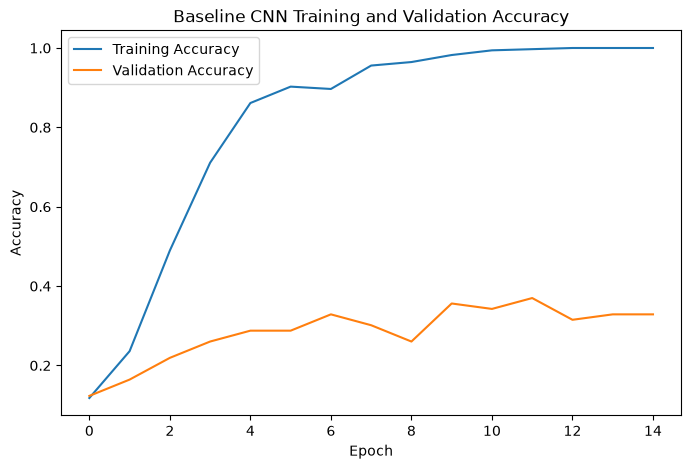

In [198]:
# Plot training and validation accuracy to see how learning changed over time

plt.figure(figsize=(8, 5))

plt.plot(baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

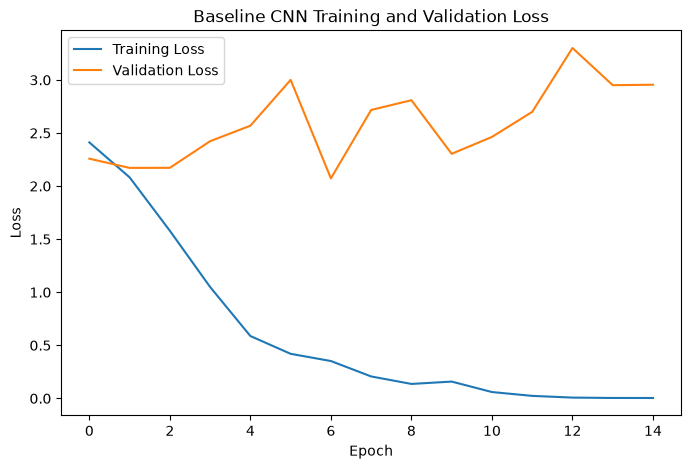

In [199]:
# Plot training and validation loss to help check for overfitting

plt.figure(figsize=(8, 5))

plt.plot(baseline_history.history["loss"], label="Training Loss")
plt.plot(baseline_history.history["val_loss"], label="Validation Loss")

plt.title("Baseline CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Baseline Training Analysis

The baseline CNN shows clear overfitting. Training accuracy increased to almost 100%, while validation accuracy remained much lower. Training loss also decreased close to zero, while validation loss increased after the earlier epochs.

This indicates that the model learned the training images very well but did not generalise effectively to unseen images. The relatively small dataset and the large number of trainable parameters are likely contributing factors.

## B4. Improved CNN

The baseline model showed strong overfitting, so a second CNN is created with techniques intended to improve generalisation. The improved model uses data augmentation, an additional convolutional layer, dropout and early stopping.

In [200]:
# Create data augmentation layers
# These slightly change training images so the model sees more variety

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [201]:
# Build an improved CNN with augmentation and dropout

improved_model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

In [202]:
# Show the structure of the improved model

improved_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### Improved CNN Architecture

The improved CNN adds data augmentation, a third convolutional layer and dropout. Data augmentation creates slightly modified versions of the training images so that the model sees more variation during training. The additional convolutional layer allows the network to learn more complex visual features, while dropout reduces reliance on individual neurons and helps reduce overfitting.

### Improved Training Strategy

The improved model uses the same Adam optimizer and sparse categorical cross-entropy loss as the baseline so that the main differences come from the architecture and regularisation techniques.

The model is allowed to train for up to 30 epochs. Early stopping monitors validation loss with a patience of four epochs and restores the best-performing weights. This allows the model enough time to learn while reducing unnecessary training once validation performance stops improving.

In [203]:
# Configure the improved model

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [204]:
# Stop training if validation loss stops improving

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

In [205]:
# Train the improved model

improved_history = improved_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.0885 - loss: 2.3458 - val_accuracy: 0.1096 - val_loss: 2.2999
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.1445 - loss: 2.2957 - val_accuracy: 0.1507 - val_loss: 2.2903
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.1445 - loss: 2.2859 - val_accuracy: 0.2603 - val_loss: 2.2637
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.1917 - loss: 2.2032 - val_accuracy: 0.2055 - val_loss: 2.1758
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.2124 - loss: 2.1557 - val_accuracy: 0.3014 - val_loss: 2.0774
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.2832 - loss: 2.0950 - val_accuracy: 0.2603 - val_loss: 2.0284
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.2950 - loss: 2.0169 - val_accuracy: 0.1918 - val_loss: 2.1870
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.2832 - loss: 2.0311 - val_accuracy: 0.2877 - 

In [206]:
# Check how many epochs the improved model was trained for
epochs_run = len(improved_history.history["loss"])
best_epoch = int(np.argmin(improved_history.history["val_loss"])) + 1

print("Improved CNN trained for", epochs_run, "epochs (maximum allowed: 30)")
print("Best validation loss at epoch", best_epoch, "- those weights were restored")
print("Training accuracy at the end:   ", round(improved_history.history["accuracy"][-1], 3))
print("Validation accuracy at the end: ", round(improved_history.history["val_accuracy"][-1], 3))

Improved CNN trained for 10 epochs (maximum allowed: 30)
Best validation loss at epoch 6 - those weights were restored
Training accuracy at the end:    0.319
Validation accuracy at the end:  0.233


In [207]:
# Evaluate the improved model on unseen test images

improved_test_loss, improved_test_accuracy = improved_model.evaluate(X_test_images, y_test_images)

print("Improved test loss:", improved_test_loss)
print("Improved test accuracy:", improved_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1781 - loss: 2.1005
Improved test loss: 2.1005043983459473
Improved test accuracy: 0.1780821979045868


### Improved CNN Test Performance

The improved CNN's test accuracy and loss are printed above and compared with the baseline model in section B6. Dropout, augmentation and early stopping were added to reduce the overfitting seen in the baseline, so the training and validation behaviour (below) is examined as well as the test result.

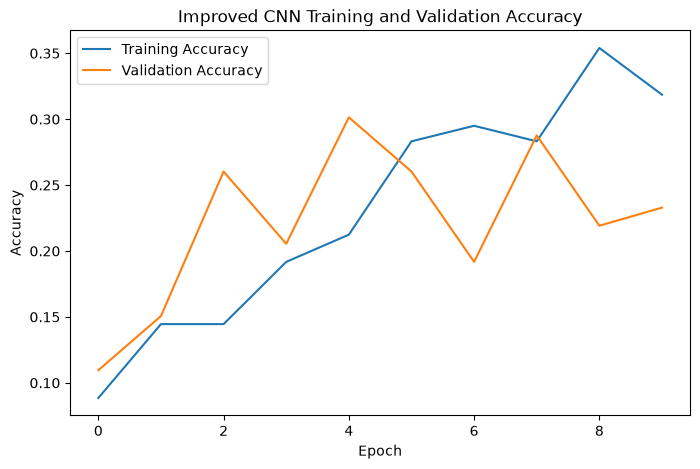

In [208]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(improved_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Improved CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

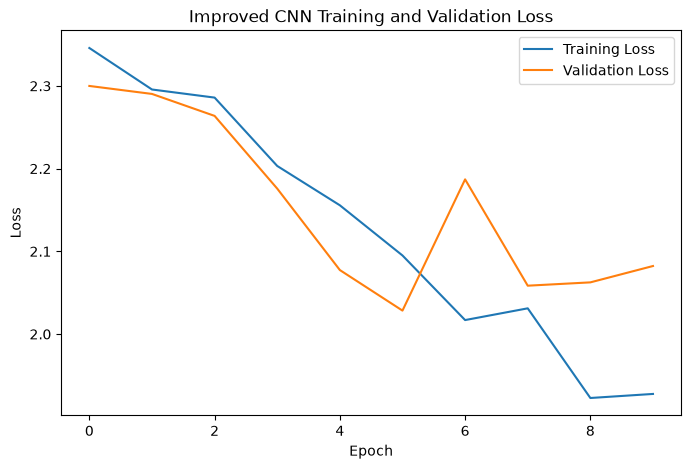

In [209]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(improved_history.history["loss"], label="Training Loss")
plt.plot(improved_history.history["val_loss"], label="Validation Loss")

plt.title("Improved CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Improved CNN Training Analysis

The improved CNN showed less severe overfitting than the baseline model. Data augmentation, dropout and early stopping reduced the gap between training and validation behaviour and prevented the model from reaching near-perfect training accuracy.

However, the test accuracy of the improved CNN remained low. This shows that regularisation improved the training behaviour, but a small dataset still limits what a CNN trained from scratch can learn. This motivates the transfer-learning model in the next section.

## B4b. Transfer Learning with MobileNetV2

Both custom CNNs were trained from scratch on only a few hundred images, which is too little data to learn good visual features. Transfer learning reuses a network that has already learned general features (edges, textures, shapes) from a very large dataset (ImageNet) and trains only a small new classifier on top. MobileNetV2 was chosen because it is small, quick to train on a CPU and accepts 128 × 128 images, so the same image size could be kept.

**Training in two stages**

1. **Stage 1:** the pretrained base is frozen and only the new classification layers are trained (learning rate 0.001).
2. **Stage 2 (fine-tuning):** the last 30 layers of the base are unfrozen and trained with a very small learning rate (0.00001), so the pretrained features are adjusted gently instead of being destroyed. Batch-normalisation layers stay frozen.

**Other choices**

- The same data augmentation as the improved CNN is used (training only).
- Pixel values are rescaled from 0–1 to −1–1 because MobileNetV2 expects that range.
- `GlobalAveragePooling2D` replaces `Flatten`, which keeps the number of trainable parameters small and reduces overfitting.
- Early stopping on validation loss is used in both stages, and the same Adam optimiser and sparse categorical cross-entropy loss as before are used.

In [210]:
# Set a random seed so the transfer learning results are reproducible

tf.keras.utils.set_random_seed(42)


# Load MobileNetV2 with the weights it learned on ImageNet
# include_top=False removes its original 1000-class classifier
# The first run downloads the weights, so an internet connection is needed

base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)


# Stage 1: keep the pretrained layers frozen

base_model.trainable = False

In [211]:
# Build the transfer learning model

transfer_model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    # Same augmentation as the improved CNN (only active during training)
    data_augmentation,

    # Change pixel values from 0 to 1 into -1 to 1, which is what MobileNetV2 expects
    layers.Rescaling(scale=2.0, offset=-1.0),

    base_model,

    # One average value per feature map instead of a very long Flatten layer
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    # 10 output neurons because we have 10 animal classes
    layers.Dense(10, activation="softmax")
])


transfer_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [212]:
# Stage 1: train only the new classification layers

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# Stop training if validation loss stops improving

transfer_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


transfer_history = transfer_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=30,
    batch_size=32,
    callbacks=[transfer_early_stopping]
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 233ms/step - accuracy: 0.1917 - loss: 2.5611 - val_accuracy: 0.5479 - val_loss: 1.5126
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6431 - loss: 1.1831 - val_accuracy: 0.8904 - val_loss: 0.6676
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7965 - loss: 0.6806 - val_accuracy: 0.9589 - val_loss: 0.3318
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8938 - loss: 0.4170 - val_accuracy: 0.9589 - val_loss: 0.2167
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9263 - loss: 0.3155 - val_accuracy: 0.9589 - val_loss: 0.1657
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9410 - loss: 0.2400 - val_accuracy: 0.9863 - val_loss: 0.1264
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9469 - loss: 0.1953 - val_accuracy: 0.9726 - val_loss: 0.1053
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9646 - loss: 0.1746 - val_accuracy: 0.9726 - 

In [213]:
# Stage 2: fine-tune the last 30 layers of MobileNetV2 with a very small learning rate

base_model.trainable = True


# The early layers stay frozen because they contain very general features

for layer in base_model.layers[:-30]:

    layer.trainable = False


# Batch-normalisation layers stay frozen so their stored statistics
# are not disturbed by the small dataset

for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):

        layer.trainable = False


# The model must be compiled again after changing which layers can be trained

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


finetune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)


finetune_history = transfer_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=20,
    batch_size=32,
    callbacks=[finetune_early_stopping]
)


print("Stage 1 epochs:", len(transfer_history.history["loss"]))
print("Stage 2 epochs:", len(finetune_history.history["loss"]))

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 254ms/step - accuracy: 0.9941 - loss: 0.0291 - val_accuracy: 0.9863 - val_loss: 0.0366
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9912 - loss: 0.0473 - val_accuracy: 0.9863 - val_loss: 0.0351
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9941 - loss: 0.0229 - val_accuracy: 0.9863 - val_loss: 0.0429
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9971 - loss: 0.0200 - val_accuracy: 0.9863 - val_loss: 0.0434
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 1.0000 - loss: 0.0201 - val_accuracy: 0.9863 - val_loss: 0.0409
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9971 - loss: 0.0152 - val_accuracy: 0.9863 - val_loss: 0.0336
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9941 - loss: 0.0207 - val_accuracy: 0.9863 - val_loss: 0.0328
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9971 - loss: 0.0113 - val_accuracy: 0.9863 - 

In [214]:
# Evaluate the transfer learning model on unseen test images

transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(X_test_images, y_test_images)

print("Transfer learning test loss:", transfer_test_loss)
print("Transfer learning test accuracy:", transfer_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 0.0084
Transfer learning test loss: 0.00841656792908907
Transfer learning test accuracy: 1.0


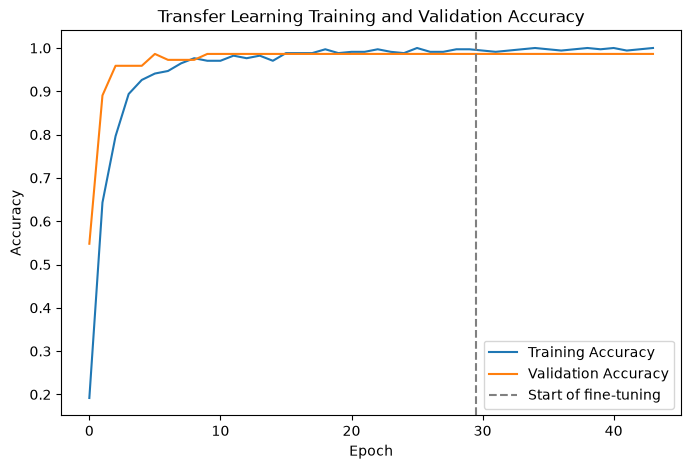

In [215]:
# Join the results of the two training stages so they can be plotted as one curve

transfer_accuracy = transfer_history.history["accuracy"] + finetune_history.history["accuracy"]

transfer_val_accuracy = transfer_history.history["val_accuracy"] + finetune_history.history["val_accuracy"]

stage_one_epochs = len(transfer_history.history["accuracy"])


plt.figure(figsize=(8, 5))

plt.plot(transfer_accuracy, label="Training Accuracy")
plt.plot(transfer_val_accuracy, label="Validation Accuracy")

# Grey line = where fine-tuning starts
plt.axvline(stage_one_epochs - 0.5, linestyle="--", color="grey", label="Start of fine-tuning")

plt.title("Transfer Learning Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

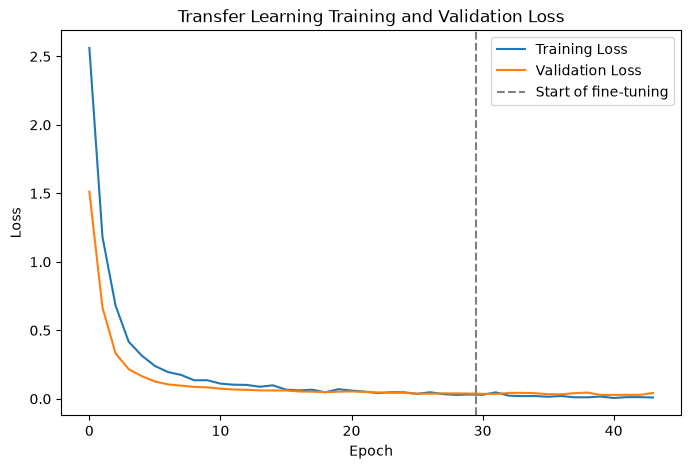

In [216]:
# Plot training and validation loss for both stages

transfer_loss = transfer_history.history["loss"] + finetune_history.history["loss"]

transfer_val_loss = transfer_history.history["val_loss"] + finetune_history.history["val_loss"]


plt.figure(figsize=(8, 5))

plt.plot(transfer_loss, label="Training Loss")
plt.plot(transfer_val_loss, label="Validation Loss")

plt.axvline(stage_one_epochs - 0.5, linestyle="--", color="grey", label="Start of fine-tuning")

plt.title("Transfer Learning Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Transfer Learning Training Analysis

The transfer learning model reached a much higher accuracy than the custom CNNs, and its training and validation curves stay close together, so the pretrained features generalised well to these images. A near-perfect score should still be treated carefully, because the validation and test sets are small and the pretrained network has seen many animals like these before. These points are discussed in section B8.

## B5. Classification Evaluation

The three models are evaluated using accuracy, precision, recall and F1-score. Confusion matrices are also used to show which animal classes are most frequently confused with one another.

In [217]:
# Import evaluation tools for classification

from sklearn.metrics import classification_report, confusion_matrix

In [218]:
# Get predicted probabilities for the test images

baseline_probabilities = baseline_model.predict(X_test_images)

# Convert probabilities into predicted class numbers
baseline_predictions = np.argmax(baseline_probabilities, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [219]:
# Show precision, recall and F1-score for each animal class

print("BASELINE CNN CLASSIFICATION REPORT")
print()

print(classification_report(
    y_test_images,
    baseline_predictions,
    target_names=class_names,
    zero_division=0
))

BASELINE CNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       0.40      0.29      0.33         7
 Appenzeller       0.22      0.57      0.32         7
         Cat       0.43      0.38      0.40         8
        Lion       0.33      0.57      0.42         7
         Pig       0.50      0.29      0.36         7
      Tigers       0.00      0.00      0.00         8
    Tortoise       0.18      0.25      0.21         8
  Toy poodle       0.38      0.43      0.40         7
  Weimaraner       0.00      0.00      0.00         7
     Whippet       0.20      0.14      0.17         7

    accuracy                           0.29        73
   macro avg       0.26      0.29      0.26        73
weighted avg       0.26      0.29      0.26        73



### Baseline Classification Results

The baseline model achieved a macro F1-score of approximately 0.26. Performance varied considerably between classes, showing that the model learned some categories more effectively than others.

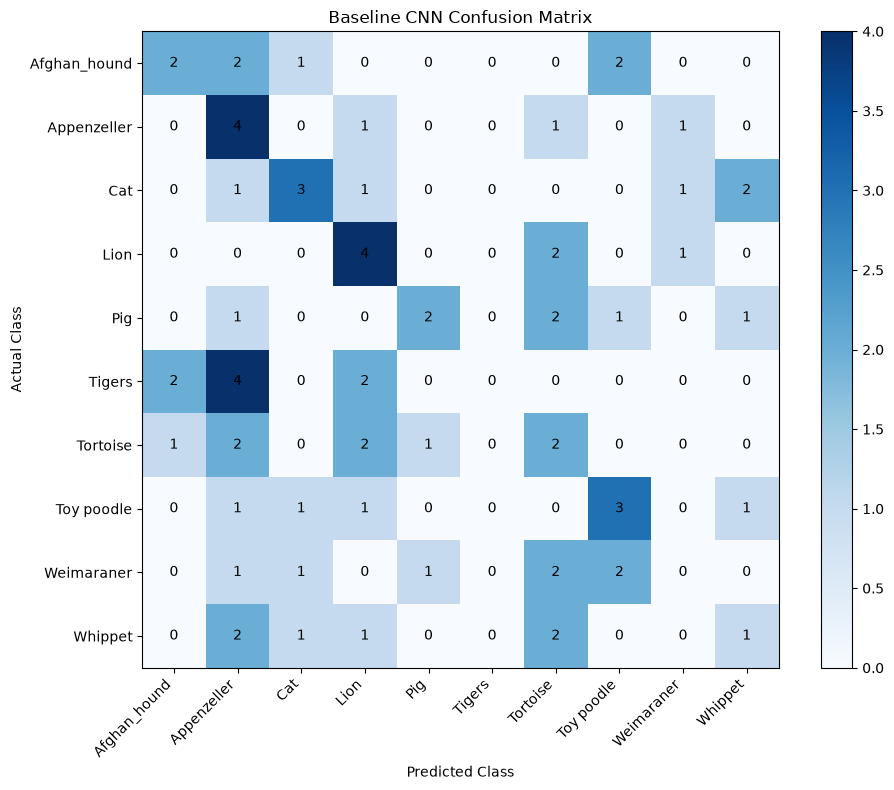

In [220]:
# Create the confusion matrix for the baseline CNN

baseline_confusion_matrix = confusion_matrix(y_test_images, baseline_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(baseline_confusion_matrix, cmap="Blues")
plt.title("Baseline CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, baseline_confusion_matrix[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

The baseline confusion matrix shows that several animal classes were frequently confused, confirming that overall performance was inconsistent across the 10 categories.

In [221]:
# Get predicted probabilities for the improved model

improved_probabilities = improved_model.predict(X_test_images)

# Convert probabilities into predicted class numbers
improved_predictions = np.argmax(improved_probabilities, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [222]:
# Show precision, recall and F1-score for each animal class

print("IMPROVED CNN CLASSIFICATION REPORT")
print()

print(classification_report(
    y_test_images,
    improved_predictions,
    target_names=class_names,
    zero_division=0
))

IMPROVED CNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       0.00      0.00      0.00         7
 Appenzeller       0.21      0.86      0.34         7
         Cat       0.07      0.12      0.09         8
        Lion       0.00      0.00      0.00         7
         Pig       0.00      0.00      0.00         7
      Tigers       0.27      0.38      0.32         8
    Tortoise       0.00      0.00      0.00         8
  Toy poodle       0.33      0.43      0.38         7
  Weimaraner       0.00      0.00      0.00         7
     Whippet       0.00      0.00      0.00         7

    accuracy                           0.18        73
   macro avg       0.09      0.18      0.11        73
weighted avg       0.09      0.18      0.11        73



### Improved Classification Results

The improved model achieved a macro F1-score of approximately 0.11. Although its test loss was lower than the baseline model, its class-level performance remained inconsistent.

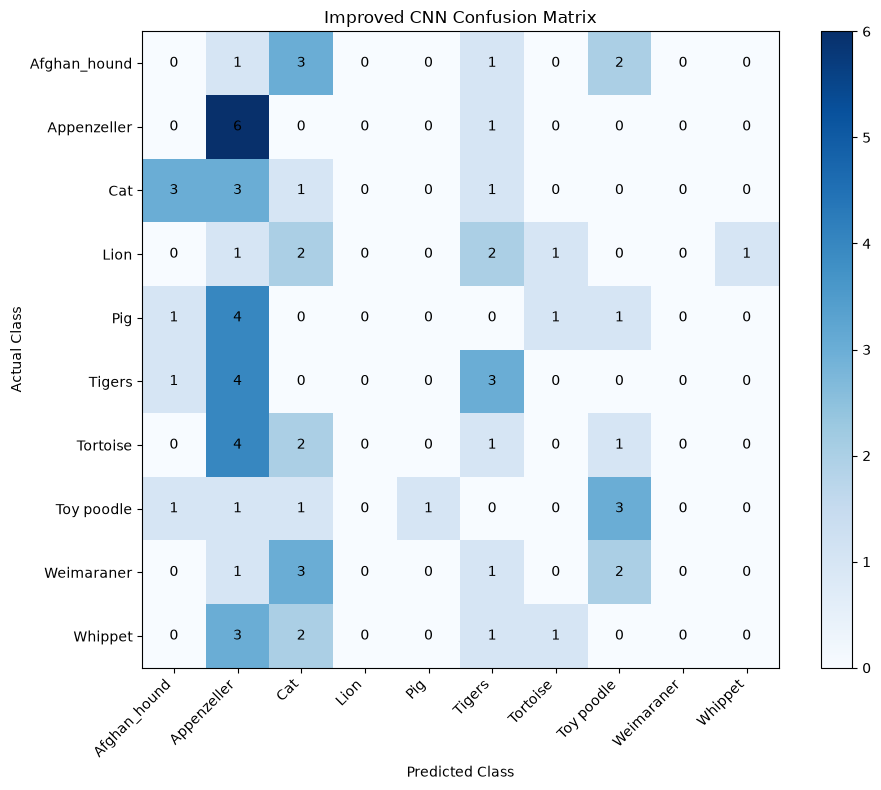

In [223]:
# Create the confusion matrix for the improved CNN

improved_confusion_matrix = confusion_matrix(y_test_images, improved_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(improved_confusion_matrix, cmap="Blues")
plt.title("Improved CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, improved_confusion_matrix[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

### Class-Level Results and Mistakes of the Improved CNN

The recall of each class shows how many of its test images the improved CNN found. The list of the most frequent mistakes shows which pairs of animals were confused with each other.

In [224]:
# Calculate the recall of each class for the improved CNN
# Recall = the share of the images of a class that were found

from sklearn.metrics import recall_score

improved_recalls = recall_score(
    y_test_images,
    improved_predictions,
    average=None,
    zero_division=0
)


for i in range( len(class_names) ):

    print( class_names[i], ":", round( improved_recalls[i], 2 ) )

Afghan_hound : 0.0
Appenzeller : 0.86
Cat : 0.12
Lion : 0.0
Pig : 0.0
Tigers : 0.38
Tortoise : 0.0
Toy poodle : 0.43
Weimaraner : 0.0
Whippet : 0.0


In [225]:
# Find the most frequent mistakes of the improved CNN
# Each mistake is (number of times, actual class, predicted class)

mistakes = []

for actual in range( len(class_names) ):

    for predicted in range( len(class_names) ):

        if actual != predicted and improved_confusion_matrix[actual, predicted] > 0:

            mistakes.append( ( improved_confusion_matrix[actual, predicted], class_names[actual], class_names[predicted] ) )


# Sort so that the most frequent mistakes come first

mistakes.sort( reverse=True )


print("Most frequent mistakes of the improved CNN:")

for count, actual, predicted in mistakes[:8]:

    print( count, "x", actual, "predicted as", predicted )

Most frequent mistakes of the improved CNN:
4 x Tortoise predicted as Appenzeller
4 x Tigers predicted as Appenzeller
4 x Pig predicted as Appenzeller
3 x Whippet predicted as Appenzeller
3 x Weimaraner predicted as Cat
3 x Cat predicted as Appenzeller
3 x Cat predicted as Afghan_hound
3 x Afghan_hound predicted as Cat


The recall values show that the improved CNN found some classes much more reliably than others: Appenzeller reached a recall of 0.86, while six classes (Afghan hound, Lion, Pig, Tortoise, Weimaraner and Whippet) had a recall of 0. Its most frequent mistake was predicting Appenzeller for many unrelated animals (tortoise, tiger, pig, whippet, cat), which suggests it was leaning towards one class and had not learned features that distinguish the animals. It also confused cats and Afghan hounds in both directions.

### Transfer Learning Classification Results

In [226]:
# Get predicted probabilities for the transfer learning model

transfer_probabilities = transfer_model.predict(X_test_images)

# Convert probabilities into predicted class numbers
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 230ms/step


In [227]:
# Show precision, recall and F1-score for each animal class

print("TRANSFER LEARNING CLASSIFICATION REPORT")
print()

print(classification_report(
    y_test_images,
    transfer_predictions,
    target_names=class_names,
    zero_division=0
))

TRANSFER LEARNING CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       1.00      1.00      1.00         7
 Appenzeller       1.00      1.00      1.00         7
         Cat       1.00      1.00      1.00         8
        Lion       1.00      1.00      1.00         7
         Pig       1.00      1.00      1.00         7
      Tigers       1.00      1.00      1.00         8
    Tortoise       1.00      1.00      1.00         8
  Toy poodle       1.00      1.00      1.00         7
  Weimaraner       1.00      1.00      1.00         7
     Whippet       1.00      1.00      1.00         7

    accuracy                           1.00        73
   macro avg       1.00      1.00      1.00        73
weighted avg       1.00      1.00      1.00        73



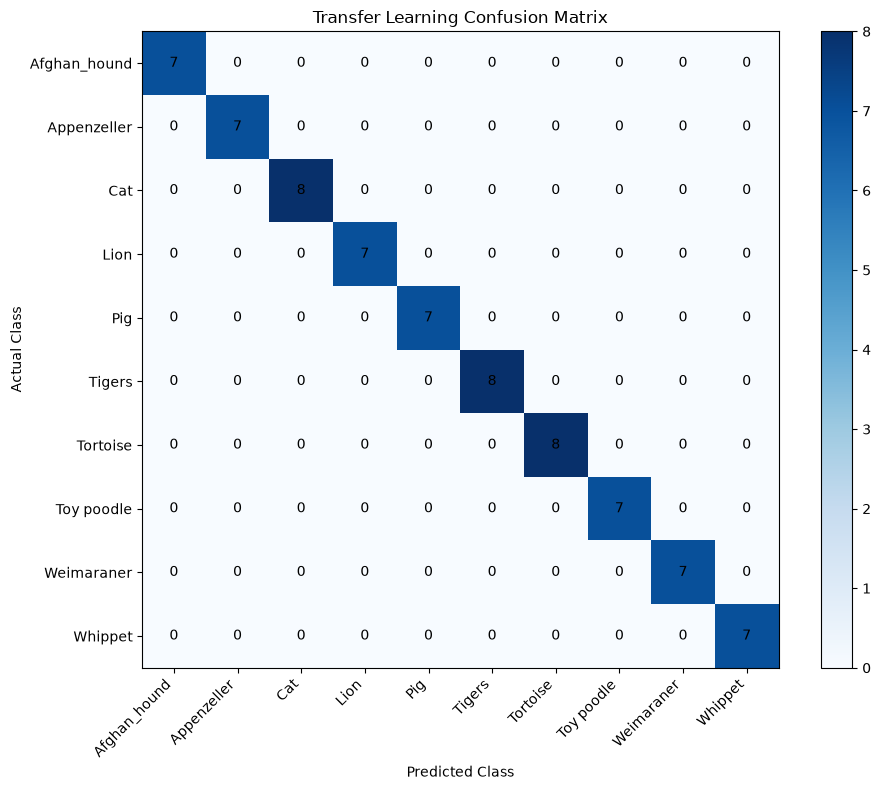

In [228]:
# Create the confusion matrix for the transfer learning model

transfer_confusion_matrix = confusion_matrix(y_test_images, transfer_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(transfer_confusion_matrix, cmap="Blues")
plt.title("Transfer Learning Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, transfer_confusion_matrix[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

The transfer learning model's class-level results are far stronger than those of the custom CNNs. Because the test set is small (each image is worth more than one percentage point), a perfect or near-perfect result means the model is very good on these images but it cannot prove it will be perfect on every new photo.

## B6. Model Comparison and Selection

In [229]:
# # Compare the main test results from both CNN models
# Calculate macro F1-scores for both models

from sklearn.metrics import f1_score

baseline_macro_f1 = f1_score(y_test_images, baseline_predictions, average="macro")
improved_macro_f1 = f1_score(y_test_images, improved_predictions, average="macro")

# Compare the main test results from both CNN models

cnn_results = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Test Accuracy": [baseline_test_accuracy, improved_test_accuracy],
    "Macro F1": [baseline_macro_f1, improved_macro_f1],
    "Test Loss": [baseline_test_loss, improved_test_loss]
})

display(cnn_results)

,Model,Test Accuracy,Macro F1,Test Loss
0,Baseline CNN,0.287671,0.261522,3.483331
1,Improved CNN,0.178082,0.112456,2.100504


### Comparison of All Three Models and Final Model Selection

All three models are compared on the validation and test sets. The final model is selected using the **validation** set, not the test set, so that the test set remains an independent check of the chosen model. The model with the highest validation macro F1-score is chosen in the cell below.

In [230]:
# Compare all three models on the validation set and the test set

cnn_names = ["Baseline CNN", "Improved CNN", "Transfer Learning (MobileNetV2)"]

cnn_models = [baseline_model, improved_model, transfer_model]


comparison_rows = []

for i in range( len(cnn_models) ):

    # Loss and accuracy
    val_loss, val_accuracy = cnn_models[i].evaluate( X_validation_images, y_validation_images, verbose=0 )

    test_loss, test_accuracy = cnn_models[i].evaluate( X_test_images, y_test_images, verbose=0 )


    # Macro F1-score needs the predicted classes
    val_predictions = np.argmax( cnn_models[i].predict( X_validation_images, verbose=0 ), axis=1 )

    test_predictions = np.argmax( cnn_models[i].predict( X_test_images, verbose=0 ), axis=1 )

    val_f1 = f1_score( y_validation_images, val_predictions, average="macro" )

    test_f1 = f1_score( y_test_images, test_predictions, average="macro" )


    comparison_rows.append([ cnn_names[i], val_accuracy, val_f1, val_loss, test_accuracy, test_f1, test_loss ])


final_comparison = pd.DataFrame(
    comparison_rows,
    columns=["Model", "Val Accuracy", "Val Macro F1", "Val Loss", "Test Accuracy", "Test Macro F1", "Test Loss"]
)

display( final_comparison.round(3) )


# Choose the model with the highest validation macro F1-score

best_cnn_index = final_comparison["Val Macro F1"].idxmax()

final_model_name = cnn_names[best_cnn_index]

final_model = cnn_models[best_cnn_index]


print("\nFinal model (chosen using the validation set):", final_model_name)

print("One test image is worth about", round(100 / len(y_test_images), 1), "percentage points of test accuracy.")

,Model,Val Accuracy,Val Macro F1,Val Loss,Test Accuracy,Test Macro F1,Test Loss
0,Baseline CNN,0.329,0.312,2.955,0.288,0.262,3.483
1,Improved CNN,0.260,0.190,2.028,0.178,0.112,2.101
2,Transfer Learning (MobileNetV2),0.986,0.987,0.028,1.000,1.000,0.008



Final model (chosen using the validation set): Transfer Learning (MobileNetV2)
One test image is worth about 1.4 percentage points of test accuracy.


### Final Model Selection

The transfer learning model had the strongest validation and test results and was therefore selected as the final model. The two custom CNNs are kept as comparison models: they show the effect of regularisation (baseline to improved CNN) and of pretrained features (improved CNN to transfer learning).

Because the test set is small, differences of a few percentage points between models are not reliable. The large gap between the custom CNNs and the transfer learning model is far larger than that, so it is a real difference.

The improved CNN did not outperform the baseline on the validation or test data, so regularisation alone did not help; the large improvement came from the pretrained features.

## B7. Unseen Image Prediction

The selected final model is tested on an image from the test set that was not used during training. The predicted class and confidence score are shown alongside the true class to demonstrate how the model performs on previously unseen data.

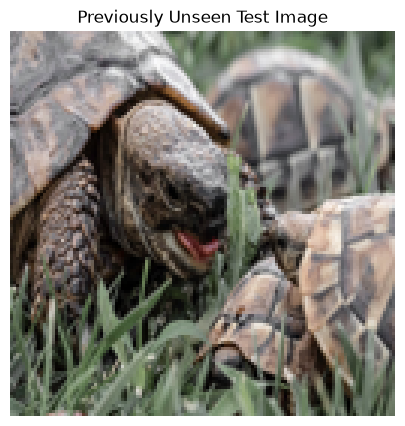

Actual class: Tortoise


In [231]:
# Choose one image from the test set that the model has never trained on

image_index = 0

unseen_image = X_test_images[image_index]
actual_class_number = y_test_images[image_index]
actual_class_name = class_names[actual_class_number]

plt.figure(figsize=(5, 5))
plt.imshow(unseen_image)
plt.title("Previously Unseen Test Image")
plt.axis("off")
plt.show()

print("Actual class:", actual_class_name)

In [232]:
# Add an extra dimension because the model expects a batch of images

image_for_prediction = np.expand_dims(unseen_image, axis=0)

# Predict the probabilities for all 10 classes using the selected final model
prediction_probabilities = final_model.predict(image_for_prediction)

# Find the class with the highest probability
predicted_class_number = np.argmax(prediction_probabilities[0])
predicted_class_name = class_names[predicted_class_number]

# Get the confidence of the prediction
confidence = prediction_probabilities[0][predicted_class_number] * 100

print("Actual class:", actual_class_name)
print("Predicted class:", predicted_class_name)
print("Confidence:", round(confidence, 2), "%")

if predicted_class_name == actual_class_name:
    print("The prediction is correct.")
else:
    print("The prediction is incorrect.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Actual class: Tortoise
Predicted class: Tortoise
Confidence: 99.95 %
The prediction is correct.


In [233]:
# Show the predicted probability for every animal class

for i in range(len(class_names)):
    probability = prediction_probabilities[0][i] * 100
    print(class_names[i], ":", round(probability, 2), "%")

Afghan_hound : 0.0 %
Appenzeller : 0.0 %
Cat : 0.02 %
Lion : 0.0 %
Pig : 0.01 %
Tigers : 0.02 %
Tortoise : 99.95 %
Toy poodle : 0.0 %
Weimaraner : 0.0 %
Whippet : 0.0 %


### Unseen Image Result

The predicted class and confidence of the selected model for this image are printed above, with the probability of every class shown below it. A near-perfect test score does not guarantee good performance on photos taken by visitors, so the model is also tested on several more test images and on two photos from outside the dataset in the cells below.

### More Test Predictions and Least Confident Predictions

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


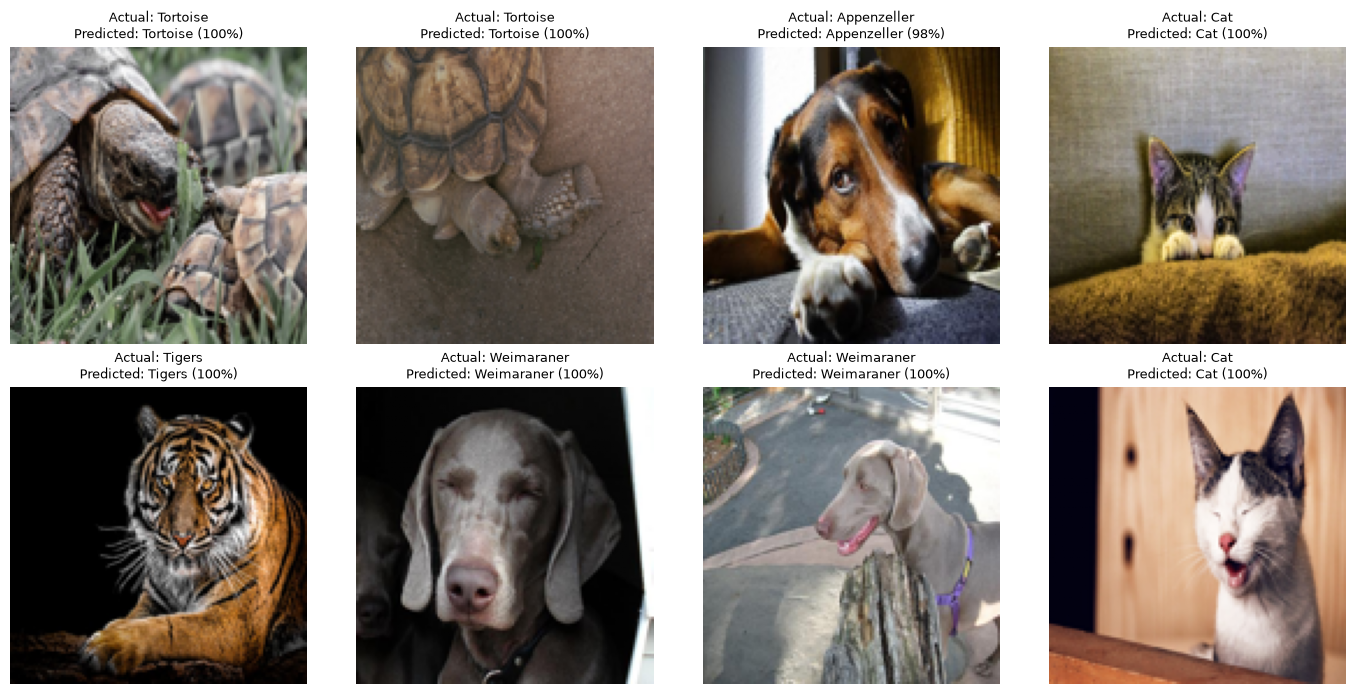

In [234]:
# Predict the classes of all test images with the final model

final_probabilities = final_model.predict(X_test_images)

final_predictions = np.argmax(final_probabilities, axis=1)

final_confidences = np.max(final_probabilities, axis=1) * 100


# Show the first 8 test images with the actual class, predicted class and confidence

plt.figure(figsize=(14, 7))

for index in range(8):

    plt.subplot(2, 4, index + 1)

    plt.imshow(X_test_images[index])

    plt.title(
        "Actual: " + class_names[y_test_images[index]] +
        "\nPredicted: " + class_names[final_predictions[index]] +
        " (" + str(round(final_confidences[index])) + "%)",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

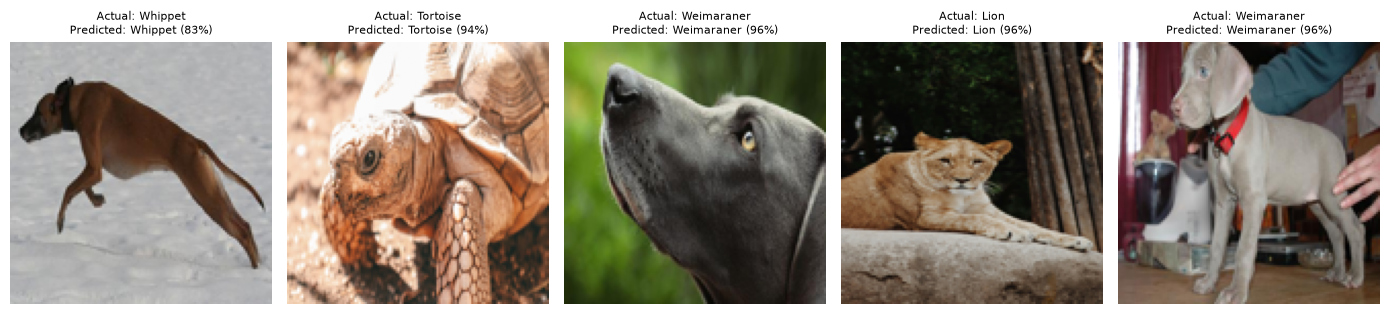

Number of misclassified test images: 0 out of 73


In [235]:
# Show the 5 test images the final model was least confident about
# These are the images most likely to be misclassified, so they show where the model is weakest

least_confident = np.argsort(final_confidences)[:5]


plt.figure(figsize=(14, 4))

for position in range( len(least_confident) ):

    index = least_confident[position]

    plt.subplot(1, 5, position + 1)

    plt.imshow(X_test_images[index])

    plt.title(
        "Actual: " + class_names[y_test_images[index]] +
        "\nPredicted: " + class_names[final_predictions[index]] +
        " (" + str(round(final_confidences[index])) + "%)",
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


print("Number of misclassified test images:", np.sum(final_predictions != y_test_images), "out of", len(y_test_images))

### Prediction on a New Photo from Outside the Dataset

To check how the model performs on photos it has never seen, two photos from outside the Image_dataset folder were tested: a cat, which is one of the ten classes, and a beagle, which is not.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


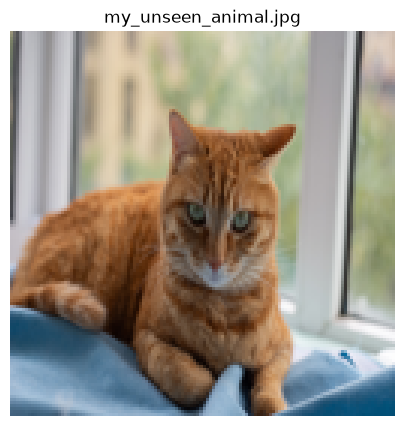

Top 3 predictions for my_unseen_animal.jpg
Cat : 100.0 %
Lion : 0.0 %
Tigers : 0.0 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


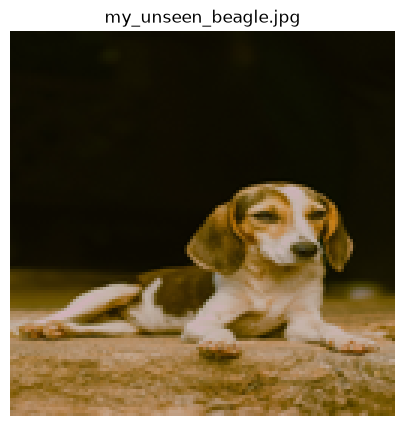

Top 3 predictions for my_unseen_beagle.jpg
Whippet : 78.75 %
Appenzeller : 18.31 %
Afghan_hound : 1.22 %


In [236]:
# New animal photos that are not in the dataset 
# The second photo shows an animal that is NOT one of the ten classes

external_image_paths = ["my_unseen_animal.jpg", "my_unseen_beagle.jpg"]


for external_image_path in external_image_paths:

    if os.path.exists(external_image_path):

        # Prepare the photo in exactly the same way as the training images

        external_image = Image.open( external_image_path ).convert( "RGB" )

        external_image = external_image.resize( ( IMAGE_SIZE, IMAGE_SIZE ) )

        external_image = np.array( external_image ) / 255.0


        # Predict the class probabilities

        external_probabilities = final_model.predict( np.expand_dims( external_image, axis=0 ) )

        top_three = np.argsort( external_probabilities[0] )[::-1][:3]


        plt.figure( figsize=(5, 5) )
        plt.imshow( external_image )
        plt.title( external_image_path )
        plt.axis("off")
        plt.show()


        print("Top 3 predictions for", external_image_path)

        for index in top_three:

            print( class_names[index], ":", round( external_probabilities[0][index] * 100, 2 ), "%" )

    else:

        print("Photo not found:", external_image_path)

The photo of a cat was classified correctly with very high confidence. The photo of a beagle, which is not one of the ten classes, was classified as a Whippet (78.75%), the most similar dog in the dataset. The model has no “unknown animal” option, so it must always pick one of the ten classes, and its confidence is not a reliable sign that the answer is correct. Real visitors may photograph animals outside the ten classes, so a rejection option is a useful future improvement.

## B8. Limitations and Future Improvements

**Dataset size and quality.** The dataset is small, with only a few hundred usable images after removing exact and near-duplicate copies. This limits the variety of poses, backgrounds and lighting the models can learn from, and it is the main reason the CNNs trained from scratch overfit and performed poorly. Removing copies also introduced a small class imbalance, so classes have slightly different numbers of images.

**Data leakage.** Exact duplicates were removed with a file hash and near-duplicates with an average hash before splitting, so copies of the same photo cannot appear in both training and test data. This hash only finds very similar images, so other similar photos (for example from the same photo shoot) may still remain.

**Reliability of the results.** The validation and test sets are small, so each test image is worth more than one percentage point and the results have a wide margin of error. The transfer learning model scored near-perfectly on both sets, so these sets cannot show how it compares with other strong models, and one split was used rather than cross-validation.

**Pretrained knowledge.** MobileNetV2 was trained on ImageNet, which already contains categories close to most of these ten animals (dog breeds, big cats, pigs, turtles). Part of the high accuracy therefore comes from knowledge the network already had, and results may be lower for animals that ImageNet does not cover or for lower-quality visitor photos.

**Class-level errors.** The improved CNN found some classes much more reliably than others and often predicted Appenzeller for unrelated animals, showing it had not learned animal-specific features. Overall accuracy hides these differences, so precision, recall and macro F1-score were reported as well.

**Future improvements.**

- Collect more images, including photos taken on mobile phones in zoo conditions.
- Use cross-validation to get a more reliable estimate of performance.
- Try other pretrained models and compare them using the same validation set.
- Use explainability methods (such as Grad-CAM) to check that the model looks at the animal rather than the background.
- Add an "unknown animal" option, because visitors may photograph animals outside the ten classes.

## Final Summary

In [237]:
print("=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)


print("\nPart A (regression):\n")

display( regression_results_full[["Model", "CV RMSE (train)", "Test RMSE", "Test R2"]].round(3) )

print("Selected regression model:", best_model_name)


print("\nPart B (image classification):\n")

display( final_comparison[["Model", "Val Macro F1", "Test Accuracy", "Test Macro F1"]].round(3) )

print("Selected classification model:", final_model_name)

FINAL RESULTS SUMMARY

Part A (regression):



,Model,CV RMSE (train),Test RMSE,Test R2
0,Linear Regression,24.267,22.957,0.833
1,Ridge Regression,24.267,22.954,0.833
2,Lasso Regression,24.261,22.940,0.833
3,Decision Tree (tuned),29.063,29.582,0.722
4,Random Forest (tuned),25.774,25.105,0.800


Selected regression model: Lasso Regression

Part B (image classification):



,Model,Val Macro F1,Test Accuracy,Test Macro F1
0,Baseline CNN,0.312,0.288,0.262
1,Improved CNN,0.190,0.178,0.112
2,Transfer Learning (MobileNetV2),0.987,1.000,1.000


Selected classification model: Transfer Learning (MobileNetV2)


In [238]:
# Save the final model so the demonstration can reload it without retraining

final_model.save("final_zoo_classifier.keras")

print("Saved final model as final_zoo_classifier.keras")

Saved final model as final_zoo_classifier.keras


## Acknowledgement of AI Use

Acknowledgement of AI Use. I used Claude (Anthropic) and ChatGPT (OpenAI) as support tools during this coursework. They were used to review my notebook and to suggest additional analyses (cross-validation, Ridge/Lasso, residual analysis, near-duplicate detection and transfer learning) and to help debug code. I ran all code myself, checked the outputs, and the results reported come from my own runs. I have reviewed and understand all the code and the report, and I take responsibility for the final submission.